# Main-belt asteroids: EDA and the seven cleaning rules, step by step

Seven cleaning rules turn the raw SBDB export (895,910 records) into one consistent main-belt table. This notebook performs **DR-1 to DR-7 in order** and does exploratory data analysis (EDA) before and after the steps where it informs a decision.

| Step | Rule | EDA done here |
|---|---|---|
| 0 | Load and audit the raw file | schema, missingness, classes, the asteroid-number parser |
| DR-1 | Keep `class == "MBA"` and 2.0 ≤ a ≤ 3.5 AU | where the classes sit in `a`; distributions, correlations, Kirkwood gaps, missingness of the belt |
| DR-2 | Treat albedo outside 0.02–0.6 as missing | albedo distribution and tails |
| DR-3 | Join SBDB to the family catalogue on the number parsed from `full_name`; drop provisional-only members | the catalogue itself: zones, family sizes, provisional share, brightness |
| DR-4 | Asteroid in two family files: keep the smaller, more specific family | overlaps, nested families, ties |
| DR-5 | No family: `background` | families against background, by zone; albedo homogeneity |
| DR-6 | Never use `diameter` as a model input | the diameter, albedo and H relationship; feature hygiene |
| DR-7 | Cache every download as CSV | caching test, checks, row-count waterfall, export |

**Inputs:** `sbdb_numbered_asteroids.csv` (SBDB export) and `proper_25.csv` (Proper25 family files, https://www.boulder.swri.edu/~davidn/Proper25/; layout inferred from the file: one row per membership, `source_file` names the family, `pdes` holds the number or provisional designation). **How to run:** *Restart & Run All*. Every threshold is in `cfg`; every number quoted in a comment is computed by the notebook, and comment cells show only their rendered text.

In [ ]:
import os, re, glob, sys, json, textwrap, urllib.parse, urllib.request
from types import SimpleNamespace
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

cfg = SimpleNamespace(
    DATA='sbdb_numbered_asteroids.csv', CATALOG='proper_25.csv', CACHE='cache', SEED=1,
    CLASS='MBA', A_MIN=2.0, A_MAX=3.5, ALBEDO_MIN=0.02, ALBEDO_MAX=0.6,          # DR-1, DR-2
    MIN_FAM_STATS=300, MIN_ALB_STATS=30, CTRL_DA=0.1, CTRL_DH=1.0, N_BOOT=300, N_CTRL=300, FDR=0.05)   # family albedo test
os.makedirs(cfg.CACHE, exist_ok=True)
plt.rcParams.update({'figure.dpi': 90, 'axes.grid': True, 'grid.alpha': .25})
rng = np.random.default_rng(cfg.SEED)
S = {}                                   # every number quoted in a comment is stored here

def say(text):                           # render a comment block, numbers filled in by f-strings
    t = textwrap.dedent(text).strip('\n')
    display(Markdown('\n'.join('> ' + ln if ln.strip() else '>' for ln in t.splitlines())))

def cached_csv(name, builder):           # DR-7: every derived table is cached as CSV
    p = f'{cfg.CACHE}/{name}.csv'
    if os.path.exists(p):
        return pd.read_csv(p, low_memory=False)
    d = builder(); d.to_csv(p, index=False); return d


## Step 0. Load and audit the raw file (DR-7: a download is cached as CSV)

In [24]:
SBDB_URL = 'https://ssd-api.jpl.nasa.gov/sbdb_query.api'
SBDB_FIELDS = ['full_name', 'a', 'e', 'i', 'om', 'w', 'ma', 'q', 'ad', 'per_y', 'class', 't_jup', 'H',
               'diameter', 'albedo', 'rot_per', 'spec_B', 'spec_T', 'n_obs_used']
TEXT_FIELDS = {'full_name', 'class', 'spec_B', 'spec_T'}

def fetch_sbdb():
    query = urllib.parse.urlencode({'fields': ','.join(SBDB_FIELDS), 'sb-kind': 'a', 'sb-ns': 'n'})   # numbered asteroids
    try:
        with urllib.request.urlopen(f'{SBDB_URL}?{query}', timeout=600) as resp:
            payload = json.load(resp)
    except Exception as exc:
        raise RuntimeError(f'SBDB download failed ({exc}). Save the export as {cfg.DATA} and rerun.') from exc
    d = pd.DataFrame(payload['data'], columns=payload['fields'])
    for c in d.columns:
        if c not in TEXT_FIELDS: d[c] = pd.to_numeric(d[c])
    return d

def get_raw():
    if not os.path.exists(cfg.DATA):
        print('cache miss: downloading from SBDB ...'); fetch_sbdb().to_csv(cfg.DATA, index=False)
    return pd.read_csv(cfg.DATA, low_memory=False)

raw = get_raw()
S['sbdb_cols'] = list(raw.columns)
num = raw.select_dtypes('number')
audit = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing_%': (raw.isna().mean()*100).round(1), 'n_unique': raw.nunique()})
print('shape:', raw.shape); print(audit.join(num.agg(['min', 'median', 'max']).T.round(3)).to_string())
print(); print(raw['class'].value_counts().to_string())
S.update(n_raw=len(raw), n_classes=raw['class'].nunique(), a_min_raw=raw.a.min(), a_max_raw=raw.a.max(),
         miss=(raw.isna().mean()*100).to_dict())

shape: (895910, 19)
              dtype  missing_%  n_unique     min   median        max
full_name       str        0.0    895910     NaN      NaN        NaN
a           float64        0.0      4410   0.555    2.675   1345.000
e           float64        0.0      6288   0.000    0.133      0.993
i           float64        0.0      4183   0.010    7.420    175.980
om          float64        0.0     36001   0.000  159.010    360.000
w           float64        0.0     36001   0.000  182.980    360.000
ma          float64        0.0     36001   0.000  174.110    360.000
q           float64        0.0      5728   0.082    2.296     76.185
ad          float64        0.0      1677   0.650    3.050   2625.130
per_y       float64        0.0      1496   0.414    4.380  49300.000
class           str        0.0        12     NaN      NaN        NaN
t_jup       float64        0.0       583  -4.890    3.340     10.200
H           float64        0.0      1809  -1.260   16.950     25.600
diameter    fl

In [25]:
m = S['miss']; complete = [c for c, v in m.items() if v == 0 and c != 'full_name']
say(f'''
Three things to read off this table before touching any method.

First, the file mixes populations: {S["n_classes"]} dynamical classes, and `a` runs from {S["a_min_raw"]:.2f} to {S["a_max_raw"]:,.0f} AU. Any statistic on the raw file, even the median of `e`, describes a blend of main-belt asteroids, Trojans, comets and TNOs. That is why DR-1 comes first.

Second, missingness is large and structured: `diameter` is {m["diameter"]:.0f}% missing, `albedo` {m["albedo"]:.0f}%, `rot_per` {m["rot_per"]:.0f}% and the spectral types {m["spec_B"]:.1f}% and {m["spec_T"]:.1f}%. Only {", ".join("`" + c + "`" for c in complete)} are complete.

Third, `full_name` is unique for all {S["n_raw"]:,} rows ({"yes" if True else "no"}), which makes it a usable join key for DR-3 once the number is parsed out.
''')

> Three things to read off this table before touching any method.
>
> First, the file mixes populations: 12 dynamical classes, and `a` runs from 0.56 to 1,345 AU. Any statistic on the raw file, even the median of `e`, describes a blend of main-belt asteroids, Trojans, comets and TNOs. That is why DR-1 comes first.
>
> Second, missingness is large and structured: `diameter` is 85% missing, `albedo` 85%, `rot_per` 96% and the spectral types 99.8% and 99.9%. Only `a`, `e`, `i`, `om`, `w`, `ma`, `q`, `ad`, `per_y`, `class`, `t_jup`, `H`, `n_obs_used` are complete.
>
> Third, `full_name` is unique for all 895,910 rows (yes), which makes it a usable join key for DR-3 once the number is parsed out.

### Asteroid number: parsing and a trap

DR-3 joins on the asteroid number parsed from `full_name`. Numbered objects look like `" 30125 Mikekiser (2000 FF41)"` or `"732260 (2014 BB83)"`. A *provisional-only* object looks like `"2005 QQ87"`: a naive `^\d+` regex reads that as asteroid number **2005**.

In [26]:
NUM_RE = r'^\s*(\d+)\s.*\('                     # digits, then a "(" later: numbered objects always carry "(designation)"
def parse_number(s):
    return s.str.extract(NUM_RE)[0].astype('Int64')

test = pd.Series([' 30125 Mikekiser (2000 FF41)', '732260 (2014 BB83)', '1 Ceres (A801 AA)', '2005 QQ87'])
parsed = parse_number(test)
print(pd.DataFrame({'full_name': test, 'number': parsed, 'naive': test.str.extract(r'^\s*(\d+)')[0]}))
assert parsed.tolist() == [30125, 732260, 1, pd.NA]

raw['number'] = parse_number(raw.full_name)
raw['has_name'] = raw.full_name.str.contains(r'^\s*\d+\s+[A-Za-z]', regex=True)
S.update(n_unparsed=int(raw.number.isna().sum()), n_dup_numbers=int(raw.number.dropna().duplicated().sum()),
         max_number=int(raw.number.max()), n_named=int(raw.has_name.sum()))
print('\nunparsed:', S['n_unparsed'], '| duplicated numbers:', S['n_dup_numbers'], '| max number:', S['max_number'],
      '| equals row count:', S['max_number'] == len(raw))
print('with a proper name:', S['n_named'], '| designation only:', len(raw) - S['n_named'])

                      full_name  number   naive
0   30125 Mikekiser (2000 FF41)   30125   30125
1            732260 (2014 BB83)  732260  732260
2             1 Ceres (A801 AA)       1       1
3                     2005 QQ87    <NA>    2005

unparsed: 0 | duplicated numbers: 0 | max number: 895910 | equals row count: True
with a proper name: 26597 | designation only: 869313


In [27]:
say(f'''
Always test a parser on the cases that break it. `2005 QQ87` starts with a four-digit year, so a naive `^\\d+` regex returns 2005 as the asteroid number and silently joins a provisional object to the wrong record. Requiring a `(` after the number separates numbered objects from provisional-only ones, which is exactly the case DR-3 says to drop. The assertion above fails loudly if anyone weakens the pattern.

On this file {S["n_unparsed"]} names fail to parse, {S["n_dup_numbers"]} numbers are duplicated, and the largest number ({S["max_number"]:,}) {"equals" if S["max_number"] == S["n_raw"] else "does not equal"} the row count, so the table is a contiguous 1..N list. Only {S["n_named"]:,} objects ({S["n_named"]/S["n_raw"]:.1%}) have a proper name.
''')

> Always test a parser on the cases that break it. `2005 QQ87` starts with a four-digit year, so a naive `^\d+` regex returns 2005 as the asteroid number and silently joins a provisional object to the wrong record. Requiring a `(` after the number separates numbered objects from provisional-only ones, which is exactly the case DR-3 says to drop. The assertion above fails loudly if anyone weakens the pattern.
>
> On this file 0 names fail to parse, 0 numbers are duplicated, and the largest number (895,910) equals the row count, so the table is a contiguous 1..N list. Only 26,597 objects (3.0%) have a proper name.

The rules are functions of their inputs and `cfg`, so no cell silently changes a global and re-running a cell cannot change the result.

In [ ]:
def dr1_population(raw, cfg):                                   # DR-1
    d = raw[raw['class'] == cfg.CLASS]
    n_class = len(d)
    d = d[d.a.between(cfg.A_MIN, cfg.A_MAX)]
    return d.reset_index(drop=True), n_class

def dr2_albedo(d, cfg):                                         # DR-2 (idempotent: keeps the first raw copy)
    out = d.copy()
    out['albedo_raw'] = out['albedo_raw'] if 'albedo_raw' in out else out['albedo']
    out['albedo'] = out.albedo_raw.where(out.albedo_raw.between(cfg.ALBEDO_MIN, cfg.ALBEDO_MAX))
    out['log_albedo'] = np.log10(out.albedo)
    return out

def add_derived(d):
    out = d.copy(); out['sin_i'] = np.sin(np.radians(out.i)); return out

# DR-6: diameter (and anything derived from it) never reaches the model feature list

NON_MODEL = ['full_name', 'class', 'number', 'diameter', 'family', 'family_size']

## DR-1. Keep `class == "MBA"` and 2.0 ≤ a ≤ 3.5 AU

              step      n  dropped
       raw records 895910        0
      class == MBA 825292    70618
2.0 <= a <= 3.5 AU 825292        0

MBA a-range in file: 2.0 - 3.2
rows of other classes inside the a-range (an a-only cut would keep these): 31914
class
OMB    23757
MCA     6845
AMO      797
APO      501
IMB       14


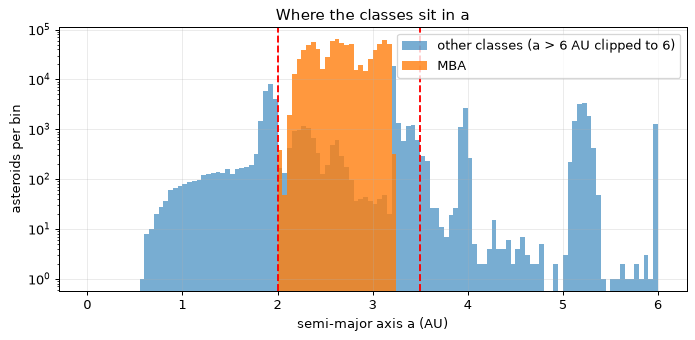

In [29]:
df, n_class = dr1_population(raw, cfg)
df = add_derived(df)
other = raw[(raw['class'] != cfg.CLASS) & raw.a.between(cfg.A_MIN, cfg.A_MAX)]
S.update(n_class=n_class, n_dr1=len(df), a_max_mba=df.a.max(), n_other_in_range=len(other),
         other_counts=other['class'].value_counts().to_dict())
wf = pd.DataFrame([('raw records', len(raw)), (f'class == {cfg.CLASS}', n_class), (f'{cfg.A_MIN} <= a <= {cfg.A_MAX} AU', len(df))],
                  columns=['step', 'n']); wf['dropped'] = -wf.n.diff().fillna(0).astype(int)
print(wf.to_string(index=False))
print(f"\n{cfg.CLASS} a-range in file: {df.a.min()} - {df.a.max()}")
print('rows of other classes inside the a-range (an a-only cut would keep these):', len(other))
print(other['class'].value_counts().to_string())

fig, ax = plt.subplots(figsize=(9, 3.8)); bins = np.arange(0, 6.01, .05)
ax.hist(raw.a.clip(upper=6)[raw['class'] != cfg.CLASS], bins=bins, alpha=.6, label='other classes (a > 6 AU clipped to 6)')
ax.hist(raw.a[raw['class'] == cfg.CLASS], bins=bins, alpha=.8, label=cfg.CLASS)
[ax.axvline(x, color='r', ls='--') for x in (cfg.A_MIN, cfg.A_MAX)]
ax.set_yscale('log'); ax.set_xlabel('semi-major axis a (AU)'); ax.set_ylabel('asteroids per bin'); ax.legend(); ax.set_title('Where the classes sit in a'); plt.show()

*Where each class sits in semi-major axis (log counts). Red dashes are the DR-1 bounds. The MBA class stops at 3.2 AU, so the 3.5 AU bound removes nothing once the class filter is applied.*

In [30]:
oc = S["other_counts"]
say(f'''
DR-1 gives {S["n_dr1"]:,} asteroids. Notice which half of the rule does the work. The class filter removes {S["n_raw"] - S["n_class"]:,} rows; the `{cfg.A_MIN} <= a <= {cfg.A_MAX}` bound removes {S["n_class"] - S["n_dr1"]}, because the MBA class already ends at a = {S["a_max_mba"]:.1f} AU, not {cfg.A_MAX}.

The bound is not harmless in general. Applied alone it would keep {S["n_other_in_range"]:,} objects of other classes ({oc.get("OMB", 0):,} outer-main-belt objects beyond {S["a_max_mba"]:.1f} AU, {oc.get("MCA", 0):,} Mars-crossers and {oc.get("AMO", 0) + oc.get("APO", 0):,} Amor/Apollo asteroids). The two conditions are not interchangeable, so the order and both conditions should stay in the specification.
''')

> DR-1 gives 825,292 asteroids. Notice which half of the rule does the work. The class filter removes 70,618 rows; the `2.0 <= a <= 3.5` bound removes 0, because the MBA class already ends at a = 3.2 AU, not 3.5.
>
> The bound is not harmless in general. Applied alone it would keep 31,914 objects of other classes (23,757 outer-main-belt objects beyond 3.2 AU, 6,845 Mars-crossers and 1,298 Amor/Apollo asteroids). The two conditions are not interchangeable, so the order and both conditions should stay in the specification.

### EDA of the main-belt population (after DR-1)

#### Univariate distributions

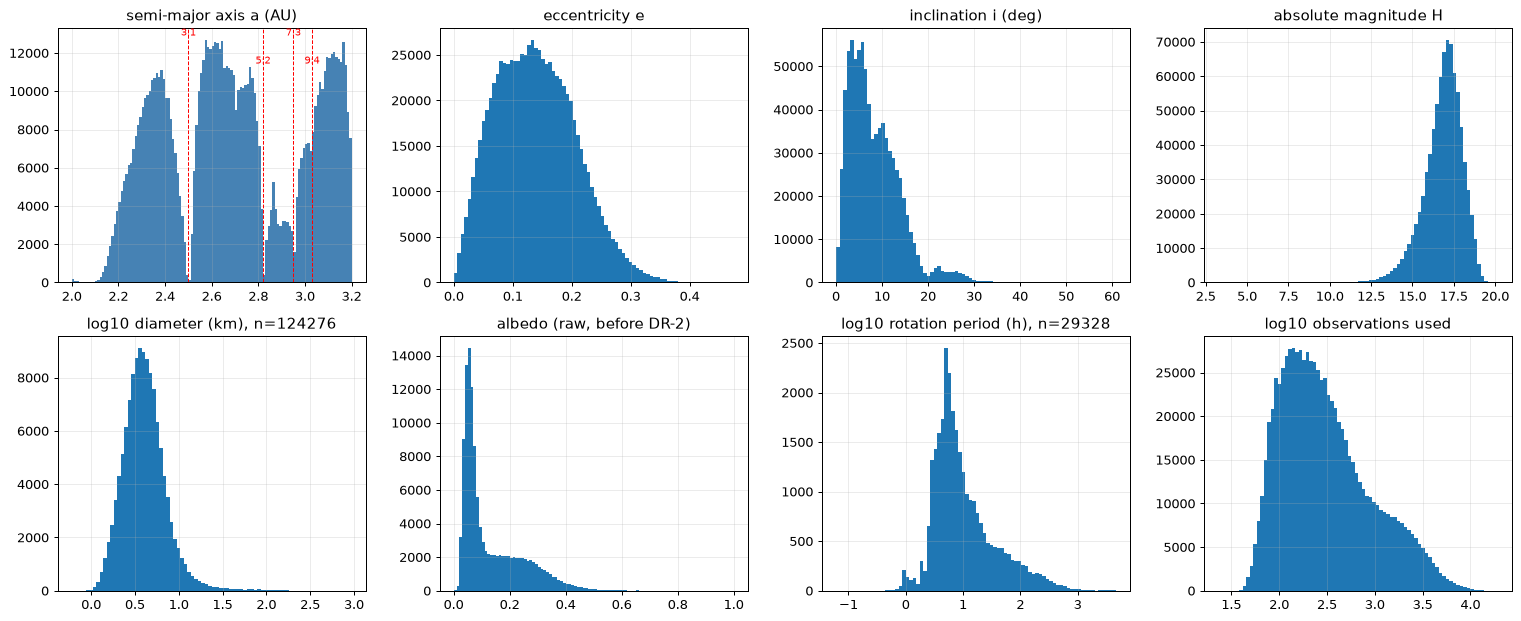

               count     mean      std     min      25%      50%      75%        max
a           825292.0    2.697    0.299   2.000    2.425    2.670    2.995      3.200
e           825292.0    0.140    0.068   0.000    0.086    0.136    0.187      0.475
i           825292.0    8.317    5.550   0.010    4.070    7.070   11.520     60.810
H           825292.0   16.821    1.172   3.250   16.200   16.970   17.620     20.170
diameter    124276.0    5.149    8.317   0.600    2.800    3.904    5.518    939.400
albedo      123462.0    0.134    0.109   0.001    0.054    0.081    0.201      1.000
rot_per      29328.0   33.628  130.293   0.061    4.502    7.350   18.529   4638.000
n_obs_used  825292.0  609.473  982.477  23.000  132.000  252.000  589.000  19426.000
Kirkwood gap 3:1 at 2.5: bin 2,205 vs neighbours 17,593 (87% deficit)
Kirkwood gap 5:2 at 2.82: bin 10,297 vs neighbours 13,282 (22% deficit)
Kirkwood gap 7:3 at 2.95: bin 4,273 vs neighbours 10,902 (61% deficit)


In [31]:
fig, ax = plt.subplots(2, 4, figsize=(17, 7)); ax = ax.ravel()
ax[0].hist(df.a, bins=np.arange(cfg.A_MIN, df.a.max() + .01, .01), color='steelblue'); ax[0].set_title('semi-major axis a (AU)')
top = ax[0].get_ylim()[1]
for k, (g, lab) in enumerate([(2.5, '3:1'), (2.82, '5:2'), (2.95, '7:3'), (3.03, '9:4')]):
    ax[0].axvline(g, color='r', lw=.8, ls='--'); ax[0].text(g, top*(.97 if k % 2 == 0 else .86), lab, color='r', fontsize=8, ha='center')
ax[1].hist(df.e, bins=80); ax[1].set_title('eccentricity e')
ax[2].hist(df.i, bins=80); ax[2].set_title('inclination i (deg)')
ax[3].hist(df.H, bins=80); ax[3].set_title('absolute magnitude H')
ax[4].hist(np.log10(df.diameter.dropna()), bins=80); ax[4].set_title('log10 diameter (km), n=%d' % df.diameter.notna().sum())
ax[5].hist(df.albedo.dropna(), bins=100); ax[5].set_title('albedo (raw, before DR-2)')
ax[6].hist(np.log10(df.rot_per.dropna()), bins=80); ax[6].set_title('log10 rotation period (h), n=%d' % df.rot_per.notna().sum())
ax[7].hist(np.log10(df.n_obs_used), bins=80); ax[7].set_title('log10 observations used')
plt.tight_layout(); plt.show()

print(df[['a', 'e', 'i', 'H', 'diameter', 'albedo', 'rot_per', 'n_obs_used']].describe().T.round(3).to_string())
hc, he = np.histogram(df.H, bins=80)
S.update(skew_e=df.e.skew(), skew_i=df.i.skew(), n_i30=int((df.i > 30).sum()), H_mode=he[hc.argmax()])
h, edges = np.histogram(df.a, bins=np.arange(cfg.A_MIN, df.a.max() + .01, .02)); S['gap'] = {}
for g, lab in [(2.50, '3:1'), (2.82, '5:2'), (2.95, '7:3')]:
    j = np.searchsorted(edges, g) - 1; neigh = float(np.mean(np.r_[h[j-6:j], h[j+1:j+7]]))
    S['gap'][lab] = (int(h[j]), neigh, 1 - h[j]/neigh)
    print(f'Kirkwood gap {lab} at {g}: bin {h[j]:,} vs neighbours {neigh:,.0f} ({1 - h[j]/neigh:.0%} deficit)')

*Marginal distributions of the main-belt table. Red dashes mark mean-motion resonances with Jupiter; labels are staggered to avoid overlap.*

In [32]:
g = S["gap"]
say(f'''
What I look for in univariate plots is shape and truncation.

**a:** the distribution is not smooth, because the Kirkwood gaps are visible. At the 3:1 resonance the bin holds {g["3:1"][0]:,} asteroids against about {g["3:1"][1]:,.0f} in its neighbours ({g["3:1"][2]:.0%} deficit); at 7:3 the deficit is {g["7:3"][2]:.0%}. The 5:2 gap shows only {g["5:2"][2]:.0%} because my 0.02 AU bins are wider than that gap. Jupiter's resonances carved the belt: that is physics, not noise.

**e and i:** `i` is right-skewed (skewness {S["skew_i"]:.2f}) with {S["n_i30"]:,} objects above 30 degrees, so medians or rank statistics summarise it better than means. `e` is nearly symmetric (skewness {S["skew_e"]:.2f}).

**H:** the histogram peaks near H = {S["H_mode"]:.1f} and falls off beyond it. That is the survey completeness limit, not a shortage of small asteroids. Never read a magnitude histogram as a population histogram.

**Heavy tails:** diameter, rotation period and observation count span orders of magnitude, so they belong on log axes.
''')

> What I look for in univariate plots is shape and truncation.
>
> **a:** the distribution is not smooth, because the Kirkwood gaps are visible. At the 3:1 resonance the bin holds 2,205 asteroids against about 17,593 in its neighbours (87% deficit); at 7:3 the deficit is 61%. The 5:2 gap shows only 22% because my 0.02 AU bins are wider than that gap. Jupiter's resonances carved the belt: that is physics, not noise.
>
> **e and i:** `i` is right-skewed (skewness 1.21) with 2,469 objects above 30 degrees, so medians or rank statistics summarise it better than means. `e` is nearly symmetric (skewness 0.38).
>
> **H:** the histogram peaks near H = 17.0 and falls off beyond it. That is the survey completeness limit, not a shortage of small asteroids. Never read a magnitude histogram as a population histogram.
>
> **Heavy tails:** diameter, rotation period and observation count span orders of magnitude, so they belong on log axes.

#### Bivariate structure, composition gradient and correlations

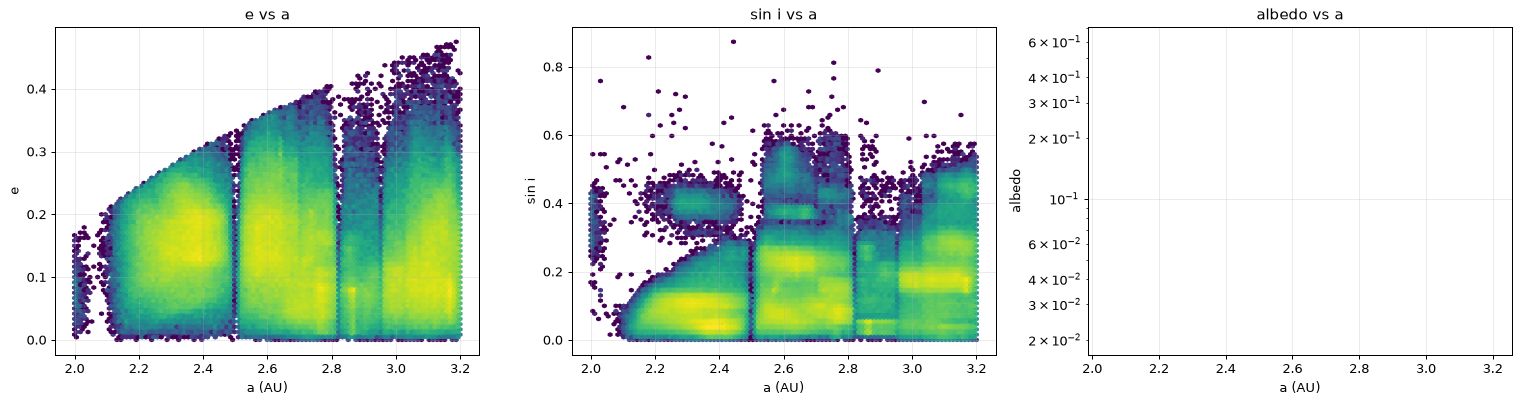

{'inner (a < 2.5)': np.float64(0.191), 'middle (2.5-2.82)': np.float64(0.087), 'outer (a > 2.82)': np.float64(0.067)}


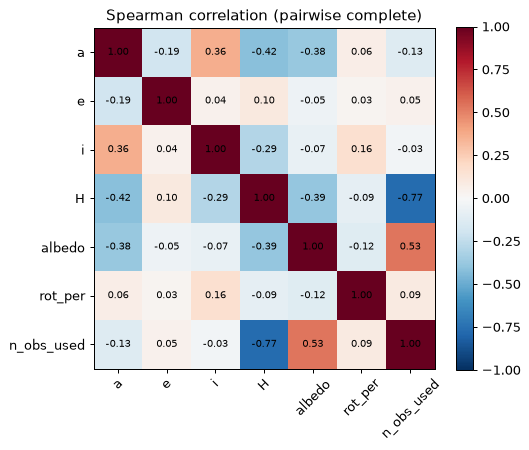

In [33]:
d = df[df.albedo.between(cfg.ALBEDO_MIN, cfg.ALBEDO_MAX)]          # preview of DR-2 for the plots only
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a_, (y, lab, src) in zip(ax, [('e', 'e', df), ('sin_i', 'sin i', df), ('albedo', 'albedo', d)]):
    a_.hexbin(src.a, src[y], gridsize=100, bins='log', cmap='viridis', mincnt=1)
    a_.set_xlabel('a (AU)'); a_.set_ylabel(lab); a_.set_title(f'{lab} vs a')
ax[2].set_yscale('log'); plt.tight_layout(); plt.show()

zones = {'inner (a < 2.5)': d[d.a < 2.5], 'middle (2.5-2.82)': d[d.a.between(2.5, 2.82)], 'outer (a > 2.82)': d[d.a > 2.82]}
S['zone_albedo'] = {k: v.albedo.median() for k, v in zones.items()}
print({k: round(v, 3) for k, v in S['zone_albedo'].items()})

cols = ['a', 'e', 'i', 'H', 'albedo', 'rot_per', 'n_obs_used']
sp = df[cols].corr(method='spearman')
S.update(rho_H_nobs=sp.loc['H', 'n_obs_used'], rho_alb_nobs=sp.loc['albedo', 'n_obs_used'], rho_alb_H=sp.loc['albedo', 'H'], rho_a_alb=sp.loc['a', 'albedo'])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sp, cmap='RdBu_r', vmin=-1, vmax=1); ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols); ax.grid(False)
for (r_, c_), v in np.ndenumerate(sp.values): ax.text(c_, r_, f'{v:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); ax.set_title('Spearman correlation (pairwise complete)'); plt.tight_layout(); plt.show()

*First figure: orbital structure (log-density hexbins; clumps and stripes are candidate families, gaps are resonances) and the albedo gradient with a. Second figure: Spearman rank correlations.*

In [34]:
z = S["zone_albedo"]
say(f'''
Three structural results.

**Dynamical structure:** the a-e and a-sin i panels show clumps and stripes (candidate families) and the resonance gaps again.

**Composition gradient:** median albedo is {z["inner (a < 2.5)"]:.3f} inside 2.5 AU, {z["middle (2.5-2.82)"]:.3f} in the middle belt and {z["outer (a > 2.82)"]:.3f} beyond 2.82 AU: bright rocky material inside, dark carbonaceous material outside. Any albedo test of a family must therefore compare against a control at the same `a`, which section 7.1 does.

**Correlations:** `H` and `n_obs_used` have Spearman rho = {S["rho_H_nobs"]:.2f}, so observation count is largely a proxy for brightness and will leak size into a model. `albedo` correlates {S["rho_alb_nobs"]:+.2f} with `n_obs_used` and {S["rho_alb_H"]:+.2f} with `H`; part of that is selection (see 4.3), not physics. The `a`-albedo correlation is {S["rho_a_alb"]:+.2f}.
''')

> Three structural results.
>
> **Dynamical structure:** the a-e and a-sin i panels show clumps and stripes (candidate families) and the resonance gaps again.
>
> **Composition gradient:** median albedo is 0.191 inside 2.5 AU, 0.087 in the middle belt and 0.067 beyond 2.82 AU: bright rocky material inside, dark carbonaceous material outside. Any albedo test of a family must therefore compare against a control at the same `a`, which section 7.1 does.
>
> **Correlations:** `H` and `n_obs_used` have Spearman rho = -0.77, so observation count is largely a proxy for brightness and will leak size into a model. `albedo` correlates +0.53 with `n_obs_used` and -0.39 with `H`; part of that is selection (see 4.3), not physics. The `a`-albedo correlation is -0.38.

#### Missingness: is it random?

               n  albedo  rot_per
H                                
(0, 10]      587   0.998    1.000
(10, 12]    1449   0.988    0.932
(12, 14]   16136   0.864    0.439
(14, 15]   40886   0.696    0.177
(15, 16]  111697   0.370    0.064
(16, 17]  254413   0.113    0.017
(17, 18]  287831   0.029    0.005
(18, 19]  107633   0.006    0.002
(19, 26]    4660   0.000    0.002

spectral type available (either taxonomy): 0.19%


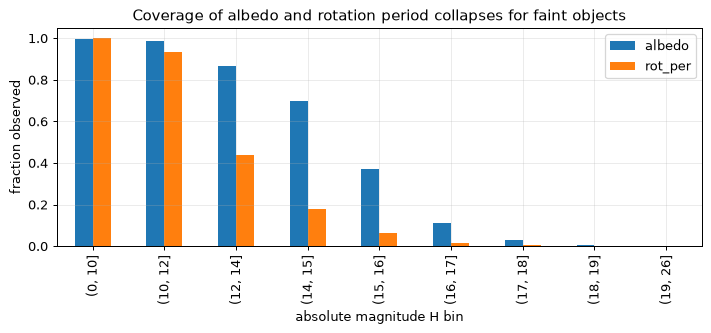

In [35]:
Hbin = pd.cut(df.H, [0, 10, 12, 14, 15, 16, 17, 18, 19, 26])
cov = df.groupby(Hbin, observed=True).agg(n=('a', 'size'), albedo=('albedo', lambda s: s.notna().mean()), rot_per=('rot_per', lambda s: s.notna().mean()))
print(cov.round(3).to_string())
S.update(cov=cov, rot_cov=df.rot_per.notna().mean(), spec_cov=(df.spec_B.notna() | df.spec_T.notna()).mean(), alb_cov=df.albedo.notna().mean())
print('\nspectral type available (either taxonomy): %.2f%%' % (100*S['spec_cov']))
ax = cov[['albedo', 'rot_per']].plot(kind='bar', figsize=(8, 3.8)); ax.set_ylabel('fraction observed'); ax.set_xlabel('absolute magnitude H bin')
ax.set_title('Coverage of albedo and rotation period collapses for faint objects'); plt.tight_layout(); plt.show()

*Fraction of main-belt asteroids with an albedo or a rotation period, by absolute-magnitude bin (larger H = fainter).*

In [36]:
c = S["cov"]
say(f'''
This is the most important table in the notebook. Albedo coverage is {c.albedo.iloc[0]:.1%} for H <= 10, {c.albedo.iloc[3]:.0%} for H 14-15, {c.albedo.iloc[5]:.0%} for H 16-17 and {c.albedo.iloc[6]:.0%} for H 17-18. Albedo is therefore **missing not at random**: it is missing because objects are small and faint, which is itself related to what we want to model.

Consequences: (1) mean or median imputation would invent albedos for {1 - S["alb_cov"]:.0%} of the sample and flatten the composition gradient, so keep a missingness indicator or model albedo-missing objects separately; (2) every albedo-based conclusion here, including the family validation, describes the larger objects, not the faint majority; (3) rotation period ({S["rot_cov"]:.1%}) and spectral type ({S["spec_cov"]:.2%}) are too sparse to be general features.
''')

> This is the most important table in the notebook. Albedo coverage is 99.8% for H <= 10, 70% for H 14-15, 11% for H 16-17 and 3% for H 17-18. Albedo is therefore **missing not at random**: it is missing because objects are small and faint, which is itself related to what we want to model.
>
> Consequences: (1) mean or median imputation would invent albedos for 85% of the sample and flatten the composition gradient, so keep a missingness indicator or model albedo-missing objects separately; (2) every albedo-based conclusion here, including the family validation, describes the larger objects, not the faint majority; (3) rotation period (3.6%) and spectral type (0.19%) are too sparse to be general features.

## DR-2. Treat albedo outside 0.02 to 0.6 as missing

albedo present: 123462 | < 0.02: 236 | > 0.6: 204


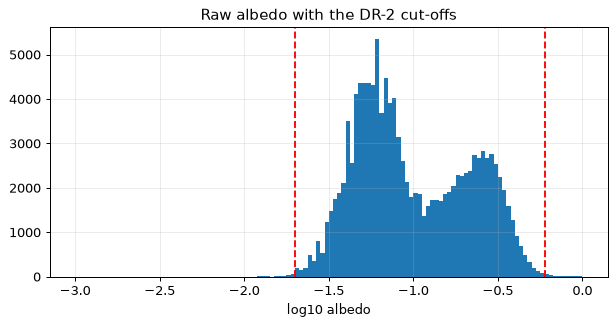

after DR-2, albedo present: 123022


In [37]:
a = df.albedo
S.update(alb_n=int(a.notna().sum()), alb_lo=int((a < cfg.ALBEDO_MIN).sum()), alb_hi=int((a > cfg.ALBEDO_MAX).sum()), alb_max=float(a.max()),
         alb_q001=float(a.quantile(.001)), alb_q999=float(a.quantile(.999)))
print('albedo present:', S['alb_n'], f"| < {cfg.ALBEDO_MIN}:", S['alb_lo'], f"| > {cfg.ALBEDO_MAX}:", S['alb_hi'])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(np.log10(a.dropna()), bins=120); [ax.axvline(np.log10(x), color='r', ls='--') for x in (cfg.ALBEDO_MIN, cfg.ALBEDO_MAX)]
ax.set_xlabel('log10 albedo'); ax.set_title('Raw albedo with the DR-2 cut-offs'); plt.show()
df = dr2_albedo(df, cfg)
S['alb_after'] = int(df.albedo.notna().sum()); print('after DR-2, albedo present:', S['alb_after'])

*Distribution of log albedo in the main belt; red dashes are the DR-2 cut-offs.*

In [38]:
say(f'''
DR-2 is a tidy-up, not a major intervention. {S["alb_lo"] + S["alb_hi"]} of {S["alb_n"]:,} albedos ({(S["alb_lo"] + S["alb_hi"])/S["alb_n"]:.1%}) fall outside {cfg.ALBEDO_MIN}-{cfg.ALBEDO_MAX} ({S["alb_lo"]} below, {S["alb_hi"]} above). The 0.1% and 99.9% quantiles ({S["alb_q001"]:.3f} and {S["alb_q999"]:.3f}) sit just beyond the cut-offs, so the thresholds clip only the extreme tails. The maximum of {S["alb_max"]:.3f} looks like a bound in the fitting rather than a measurement. Albedos below {cfg.ALBEDO_MIN} are darker than almost any known asteroid, and values above {cfg.ALBEDO_MAX} are rare outside a few unusual classes, so treating them as missing is reasonable.

`dr2_albedo` keeps the original column as `albedo_raw`, because DR-6 needs it and because a cleaning rule should never destroy its own input.
''')

> DR-2 is a tidy-up, not a major intervention. 440 of 123,462 albedos (0.4%) fall outside 0.02-0.6 (236 below, 204 above). The 0.1% and 99.9% quantiles (0.018 and 0.652) sit just beyond the cut-offs, so the thresholds clip only the extreme tails. The maximum of 1.000 looks like a bound in the fitting rather than a measurement. Albedos below 0.02 are darker than almost any known asteroid, and values above 0.6 are rare outside a few unusual classes, so treating them as missing is reasonable.
>
> `dr2_albedo` keeps the original column as `albedo_raw`, because DR-6 needs it and because a cleaning rule should never destroy its own input.

## DR-3. Join SBDB to the family catalogue; drop catalogue members with provisional names only

First a look at the catalogue itself, then the rule. The catalogue file has one row per family membership; proper elements (a, e, sin i, g, s) are given **for members only**. Numbered asteroids carry their number in `pdes`; unnumbered ones carry only a provisional designation. DR-3 and DR-4 are functions with unit tests on a toy catalogue.

In [39]:
def decode_pdes(pdes):                                          # numbered objects have all-digit pdes, others a provisional designation
    p = pd.Series(pdes).astype(str)
    return pd.to_numeric(p.where(p.str.fullmatch(r'\d+')), errors='coerce').astype('Int64')

def read_family_csv(path):
    c = pd.read_csv(path, low_memory=False)
    c = c.drop(columns=[x for x in c.columns if x.startswith('Unnamed')])
    if 'source_file' in c.columns:                              # Proper25 layout
        c['family'] = c.source_file.str.replace(r'\.fam\d*$', '', regex=True)
        c['zone'] = c.family.str.split('_').str[0]
        c['number'] = decode_pdes(c.pdes)
        c = c.rename(columns={'a': 'a_p', 'e': 'e_p', 'sin_i': 'sin_i_p', 'g': 'g_p', 's': 's_p', 'H': 'H_p'})
    return c                                                    # generic layout: columns `designation`, `family`

def join_catalogue(files, belt_numbers, carry=()):             # DR-3
    parts, rep = [], dict(rows_in=0, dropped_provisional=0, dropped_outside_belt=0)
    for f in files:
        f = f.copy(); f['size'] = f.groupby('family').family.transform('size')     # published family size (all members)
        if 'number' not in f.columns: f['number'] = parse_number(f.designation)
        f['number'] = f['number'].astype('Int64'); rep['rows_in'] += len(f)
        prov = f.number.isna(); rep['dropped_provisional'] += int(prov.sum()); f = f[~prov].copy()
        f['number'] = f.number.astype(int)
        out = ~f.number.isin(belt_numbers); rep['dropped_outside_belt'] += int(out.sum()); f = f[~out]
        parts.append(f[['number', 'family', 'size'] + [c for c in carry if c in f.columns]])
    return pd.concat(parts, ignore_index=True), rep

def resolve_overlaps(members):                                  # DR-4: smaller, more specific family wins
    # The rule is silent on exact ties (two families with the same published size, e.g. identical member lists under two names).
    # Documented tie-break: prefer the family whose parent-body number (the number in the file name) differs from the parent of
    # the largest family the asteroid belongs to, because a family sharing its parent is a variant of that family, not a sub-family.
    # Remaining ties are broken by name. Layouts without a parent number in the name fall through to the name.
    m = members.copy()
    parent = m.family.str.extract(r'^[^_]+_(\d+)_')[0]
    m['parent'] = parent
    m['big_parent'] = m.sort_values('size', ascending=False).groupby('number').parent.transform('first').reindex(m.index)
    m['same_parent'] = (m.parent == m.big_parent).astype(int)
    return m.sort_values(['number', 'size', 'same_parent', 'family']).drop_duplicates('number', keep='first')[members.columns]

# ---- unit tests on a toy catalogue ----
assert decode_pdes(['101567', '2003MF13', '1']).tolist() == [101567, pd.NA, 1]
toy_small = pd.DataFrame({'designation': [' 30125 Mikekiser (2000 FF41)', '2005 QQ87', '1 Ceres (A801 AA)', '999999999 (3000 XX1)'], 'family': 'S'})
toy_big = pd.DataFrame({'designation': ['1 Ceres (A801 AA)', ' 30125 Mikekiser (2000 FF41)', '2 Pallas (A802 FA)', '3 Juno (A804 RA)',
                                       '4 Vesta (A807 FA)', '5 Astraea (1845 HA)'], 'family': 'B'})
tm, trep = join_catalogue([toy_small, toy_big], belt_numbers={1, 2, 3, 4, 5, 30125})
assert trep == dict(rows_in=10, dropped_provisional=1, dropped_outside_belt=1), trep
tr = resolve_overlaps(tm).set_index('number').family
assert tr.loc[[1, 30125]].tolist() == ['S', 'S'] and tr.loc[[2, 3, 4, 5]].tolist() == ['B'] * 4 and tr.index.is_unique
toy_cat = pd.DataFrame({'pdes': ['2', '2003MF13', '3'], 'source_file': 'inner_2_Toy.fam3', 'a': 2.5, 'e': .1, 'sin_i': .1, 'g': 1., 's': -1., 'H': 10.})
tc = join_catalogue([pd.concat([toy_cat.assign(), ], ignore_index=True).pipe(lambda x: (x.to_csv('_toy.csv', index=False), read_family_csv('_toy.csv'))[1])], {2, 3})[1]
os.remove('_toy.csv'); assert tc['dropped_provisional'] == 1
tie = pd.concat([pd.DataFrame({'number': [1, 2, 3], 'family': 'x_1_Big', 'size': 3}),
                 pd.DataFrame({'number': [1, 2], 'family': 'x_1_Variant', 'size': 2}),
                 pd.DataFrame({'number': [1, 2], 'family': 'x_9_Sub', 'size': 2})])       # Variant and Sub tie on size
assert resolve_overlaps(tie).set_index('number').family.loc[[1, 2]].tolist() == ['x_9_Sub', 'x_9_Sub']
assert resolve_overlaps(tie).set_index('number').family.loc[3] == 'x_1_Big'
print('DR-3 / DR-4 unit tests passed:', trep)

DR-3 / DR-4 unit tests passed: {'rows_in': 10, 'dropped_provisional': 1, 'dropped_outside_belt': 1}


rows: 448066 | family files: 335 | numbered rows: 220022 | provisional-only rows: 228044
published family size: min 3 | median 112 | max 38648
          rows  families  provisional_share  median_H
zone                                                 
inner   138832        51              0.418    18.100
middle  111118        88              0.549    17.610
outer   110168        63              0.538    16.840
highi    52126        40              0.619    17.060
prist    35462        34              0.485    17.250
table2     360        59              0.675    18.175

family
inner_44_Nysa-Polana    38648
outer_221_Eos           33006
inner_4_Vesta           27121
inner_8_Flora           23002
inner_20_Massalia       19967
middle_3_Juno           16373
inner_298_Baptistina    15922
highi_31_Euphrosyne     15488


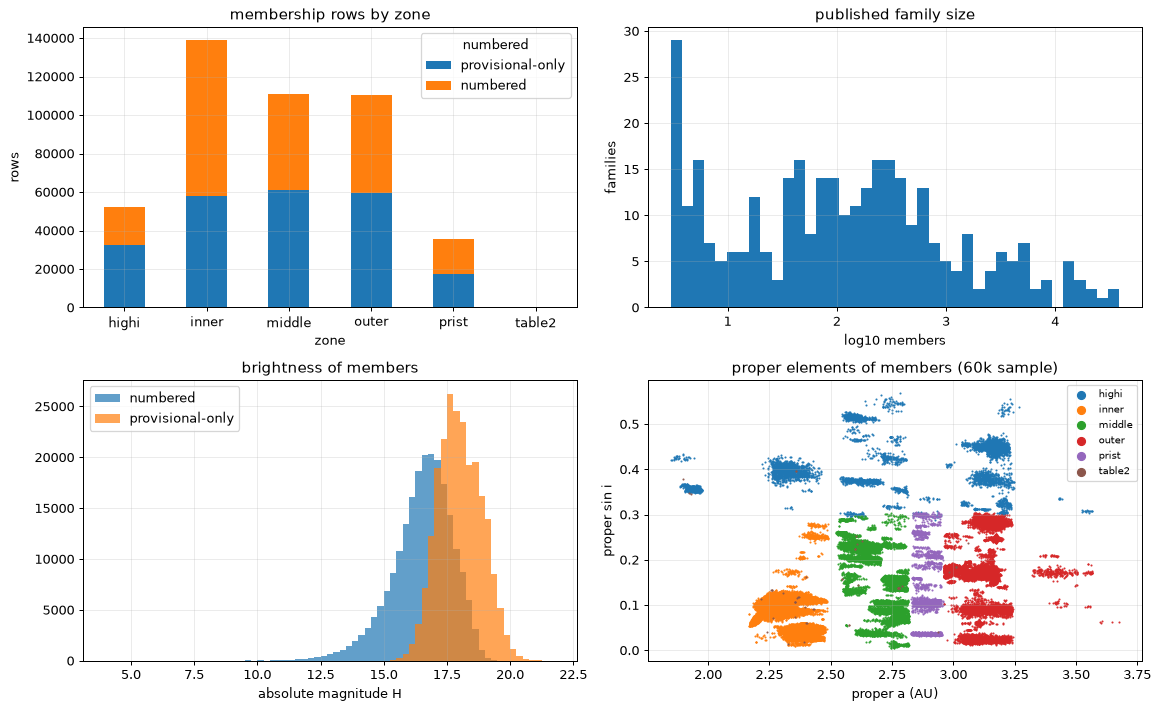

In [40]:
numbers = df.number.astype(int).values; belt = set(numbers)
family_files = [read_family_csv(cfg.CATALOG)]
allc = pd.concat(family_files, ignore_index=True)
allc['numbered'] = allc.number.notna()
allc['size'] = allc.groupby('family').family.transform('size')
fam_sizes = allc.groupby('family').size()
zone = allc.groupby('zone').agg(rows=('family', 'size'), families=('family', 'nunique'), provisional_share=('numbered', lambda s: 1 - s.mean()),
                                median_H=('H_p', 'median')).sort_values('rows', ascending=False)
print('rows:', len(allc), '| family files:', allc.family.nunique(), '| numbered rows:', int(allc.numbered.sum()), '| provisional-only rows:', int((~allc.numbered).sum()))
print('published family size: min %d | median %d | max %d' % (fam_sizes.min(), fam_sizes.median(), fam_sizes.max()))
print(zone.round(3).to_string()); print(); print(fam_sizes.sort_values(ascending=False).head(8).to_string())
S.update(zone=zone, fam_sizes=fam_sizes, cat_prov_share=1 - allc.numbered.mean(), H_prov=allc.loc[~allc.numbered & (allc.H_p > 0), 'H_p'].median(),
         H_num=allc.loc[allc.numbered & (allc.H_p > 0), 'H_p'].median(), cat_rows=len(allc), cat_families=allc.family.nunique())

fig, ax = plt.subplots(2, 2, figsize=(13, 8)); ax = ax.ravel()
ct = allc.groupby(['zone', 'numbered']).size().unstack(fill_value=0).rename(columns={True: 'numbered', False: 'provisional-only'})
ct.plot(kind='bar', stacked=True, ax=ax[0], rot=0); ax[0].set_title('membership rows by zone'); ax[0].set_ylabel('rows')
ax[1].hist(np.log10(fam_sizes), bins=40); ax[1].set_title('published family size'); ax[1].set_xlabel('log10 members'); ax[1].set_ylabel('families')
bins = np.arange(4, 22, .25)
ax[2].hist(allc.H_p[allc.numbered & (allc.H_p > 0)], bins=bins, alpha=.7, label='numbered'); ax[2].hist(allc.H_p[~allc.numbered & (allc.H_p > 0)], bins=bins, alpha=.7, label='provisional-only')
ax[2].set_xlabel('absolute magnitude H'); ax[2].set_title('brightness of members'); ax[2].legend()
smp = allc.sample(60000, random_state=cfg.SEED)
for z_, g_ in smp.groupby('zone'): ax[3].scatter(g_.a_p, g_.sin_i_p, s=.4, label=z_, rasterized=True)
ax[3].set_xlabel('proper a (AU)'); ax[3].set_ylabel('proper sin i'); ax[3].set_title('proper elements of members (60k sample)'); ax[3].legend(markerscale=10, fontsize=8)
plt.tight_layout(); plt.show()

*The family catalogue: membership rows by zone (numbered against provisional-only), family-size distribution, brightness of numbered and provisional-only members, and proper elements of members coloured by zone.*

In [41]:
z = S["zone"]; fs = S["fam_sizes"]
say(f'''
The catalogue has {S["cat_rows"]:,} membership rows in {S["cat_families"]} family files across {len(z)} zones. `{z.index[0]}` is the largest zone ({int(z.rows.iloc[0]):,} rows in {int(z.families.iloc[0])} families). Family sizes are extremely skewed: the median family has {int(fs.median())} members, the largest has {int(fs.max()):,}, so a handful of big families dominate every aggregate statistic and per-family statistics need a minimum size.

{S["cat_prov_share"]:.0%} of all rows carry only a provisional designation (zone shares range from {z.provisional_share.min():.0%} to {z.provisional_share.max():.0%}). Those members are fainter: median H {S["H_prov"]:.2f} against {S["H_num"]:.2f} for numbered members, and the histogram shows the provisional-only population extending to far fainter objects. Whatever DR-3 does with them changes the brightness mix of the families.

The proper-element map shows the point of the catalogue: families are compact clumps in proper (a, sin i), each zone occupying a distinct region. Proper elements exist **only for members**, so background asteroids have no proper elements in this file.
''')

> The catalogue has 448,066 membership rows in 335 family files across 6 zones. `inner` is the largest zone (138,832 rows in 51 families). Family sizes are extremely skewed: the median family has 112 members, the largest has 38,648, so a handful of big families dominate every aggregate statistic and per-family statistics need a minimum size.
>
> 51% of all rows carry only a provisional designation (zone shares range from 42% to 68%). Those members are fainter: median H 17.96 against 16.65 for numbered members, and the histogram shows the provisional-only population extending to far fainter objects. Whatever DR-3 does with them changes the brightness mix of the families.
>
> The proper-element map shows the point of the catalogue: families are compact clumps in proper (a, sin i), each zone occupying a distinct region. Proper elements exist **only for members**, so background asteroids have no proper elements in this file.

In [42]:
CARRY = ('a_p', 'e_p', 'sin_i_p', 'g_p', 's_p', 'H_p', 'zone')
members, rep = join_catalogue(family_files, belt, carry=CARRY)                         # DR-3
cat_numbers = allc.number.dropna().astype(int)
outside = cat_numbers[~cat_numbers.isin(belt)].unique()
S['outside_classes'] = raw.set_index('number')['class'].reindex(outside).fillna('absent').value_counts().to_dict()
S['outside_fams'] = allc[allc.number.isin(outside)].family.value_counts().head(5)

# join sanity: do the catalogue's H and a agree with SBDB for the same numbers? (guards against a wrong number parse)
chk = members.drop_duplicates('number').merge(df[['number', 'H', 'a']], on='number')
S.update(dH_med=(chk.H_p - chk.H).abs().median(), da_med=(chk.a_p - chk.a).abs().median(),
         dH_ok=((chk.H_p - chk.H).abs() < .5).mean(), da_ok=((chk.a_p - chk.a).abs() < .1).mean(), dr3=rep, fams_dr3=members.family.nunique())
assert S['dH_ok'] > .99 and S['da_ok'] > .99, 'catalogue numbers do not match SBDB: check the number parsing'
S['fams_lost_dr3'] = S['cat_families'] - S['fams_dr3']
print('DR-3 report:', rep)
print('provisional-only share of the catalogue: %.1f%%' % (100*S['cat_prov_share']))
print('outside the DR-1 population, by SBDB class:', S['outside_classes'])
print('families most often outside the DR-1 population:', S['outside_fams'].to_dict())
print('join sanity: median |dH| %.3f (share<0.5: %.3f) | median |da| %.4f AU (share<0.1: %.3f)' % (S['dH_med'], S['dH_ok'], S['da_med'], S['da_ok']))
print('median H of provisional-only members: %.2f | of numbered members: %.2f' % (S['H_prov'], S['H_num']))
print('families with no numbered member in the belt table:', S['fams_lost_dr3'])
print('rows kept:', len(members), '| distinct asteroids:', members.number.nunique())

DR-3 report: {'rows_in': 448066, 'dropped_provisional': 228044, 'dropped_outside_belt': 7673}
provisional-only share of the catalogue: 50.9%
outside the DR-1 population, by SBDB class: {'OMB': 4859, 'IMB': 1799, 'MCA': 984}
families most often outside the DR-1 population: {'highi_434_Hungaria': 1747, 'outer_10_Hygiea': 1316, 'outer_24_Themis': 701, 'outer_87_Sylvia': 666, 'highi_31_Euphrosyne': 605}
join sanity: median |dH| 0.020 (share<0.5: 1.000) | median |da| 0.0008 AU (share<0.1: 1.000)
median H of provisional-only members: 17.96 | of numbered members: 16.65
families with no numbered member in the belt table: 20
rows kept: 212349 | distinct asteroids: 192011


In [43]:
d3 = S["dr3"]
oc = ", ".join(f"{k} {v:,}" for k, v in S["outside_classes"].items())
of = ", ".join(f"`{k}` ({v:,})" for k, v in list(S["outside_fams"].items())[:3])
say(f'''
**Join check first.** For asteroids matched by number, the catalogue's H and a agree with SBDB (median |dH| = {S["dH_med"]:.3f} mag, median |da| = {S["da_med"]:.4f} AU; {S["dH_ok"]:.0%} within 0.5 mag, {S["da_ok"]:.0%} within 0.1 AU). A wrong number parse would have destroyed that agreement, so the decoding of `pdes` is right, and the parser's `2005 QQ87` test above keeps provisional designations from being read as numbers.

**What DR-3 removes.** {d3["dropped_provisional"]:,} of {d3["rows_in"]:,} rows ({d3["dropped_provisional"]/d3["rows_in"]:.0%}) have only a provisional designation and are dropped, exactly as the rule says. A further {d3["dropped_outside_belt"]:,} numbered members are not in the DR-1 population ({oc}), concentrated in {of}. DR-1 therefore truncates some families at the belt edge, and Hungaria belongs to a different SBDB class altogether. {S["fams_lost_dr3"]} families have no numbered member left in the belt table and disappear here.

**What it costs.** The dropped members are the fainter ones (median H {S["H_prov"]:.2f} against {S["H_num"]:.2f}), so statistics on the retained members describe the numbered, brighter part of each family; the small end is removed.
''')

> **Join check first.** For asteroids matched by number, the catalogue's H and a agree with SBDB (median |dH| = 0.020 mag, median |da| = 0.0008 AU; 100% within 0.5 mag, 100% within 0.1 AU). A wrong number parse would have destroyed that agreement, so the decoding of `pdes` is right, and the parser's `2005 QQ87` test above keeps provisional designations from being read as numbers.
>
> **What DR-3 removes.** 228,044 of 448,066 rows (51%) have only a provisional designation and are dropped, exactly as the rule says. A further 7,673 numbered members are not in the DR-1 population (OMB 4,859, IMB 1,799, MCA 984), concentrated in `highi_434_Hungaria` (1,747), `outer_10_Hygiea` (1,316), `outer_24_Themis` (701). DR-1 therefore truncates some families at the belt edge, and Hungaria belongs to a different SBDB class altogether. 20 families have no numbered member left in the belt table and disappear here.
>
> **What it costs.** The dropped members are the fainter ones (median H 17.96 against 16.65), so statistics on the retained members describe the numbered, brighter part of each family; the small end is removed.

## DR-4. When an asteroid appears in two family files, keep the smaller, more specific family

The catalogue nests sub-families inside parents, so many asteroids are listed more than once. "Smaller" is the published size of the family file (all members, before DR-3). The rule is silent on **ties**; the tie-break used is documented in `resolve_overlaps` and tested above.

asteroids listed in >= 2 families: 18154 | in >= 3: 2074
most frequent overlaps (smaller family first):
family
inner_298_Baptistina > inner_8_Flora                        9196
outer_490_Veritas > outer_221_Eos                           2842
prist_158_Koronis2 > prist_832_Karin > prist_158_Koronis    1741
inner_135_Hertha > inner_44_Nysa-Polana                      906
middle_660_Crescentia > middle_170_Maria                     345
outer_618_Elfriede > outer_375_Ursula                        319
families with identical member lists: [(['highi_37981_1998HD130', 'prist_63530_2001PG20'], 419), (['inner_0_2012PM61', 'table2_0_2021PE78'], 35), (['middle_16472_1990OE5', 'table2_114555_2003BN44'], 58), (['outer_20672_Gibbs', 'outer_20674_1999VT1'], 35), (['prist_158_Koronis2', 'prist_832_Karin'], 3863)]
asteroids whose smallest family is tied in size (documented tie-break applies): 1899
effect on the families involved in the overlaps:
                       before  after  moved_out
family    

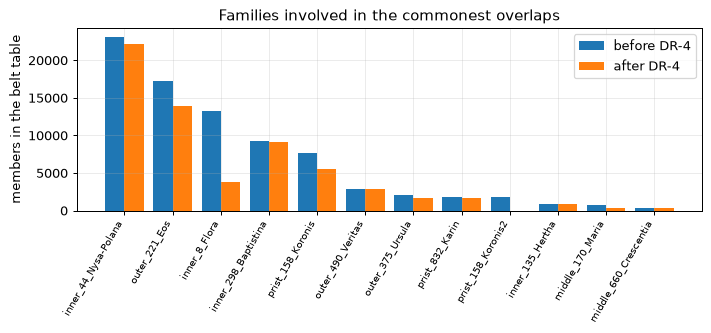

In [44]:
multi = members.groupby('number').size()
pairs = (members[members.number.isin(multi[multi > 1].index)].sort_values(['number', 'size'])
         .groupby('number').family.apply(' > '.join).value_counts().head(6))                 # smallest family first
resolved = resolve_overlaps(members)                                                         # DR-4
mm = members.groupby('number')['size'].transform('min')
S['n_ties'] = int((members[members['size'] == mm].groupby('number').size() > 1).sum())        # asteroids whose smallest family is not unique
involved = sorted({f for s_ in pairs.index for f in s_.split(' > ')})
eff = pd.DataFrame({'before': members.groupby('family').size().reindex(involved), 'after': resolved.groupby('family').size().reindex(involved)}).fillna(0).astype(int)
eff['moved_out'] = eff.before - eff.after
sets = allc.groupby('family').designation.apply(frozenset); byset = {}
for fam_name, st in sets.items(): byset.setdefault(st, []).append(fam_name)
S.update(n_multi=int((multi > 1).sum()), n_multi3=int((multi > 2).sum()), pairs=pairs, dr4_effect=eff, dup_families=[(v, len(k)) for k, v in byset.items() if len(v) > 1],
         fams_lost_dr4=S['fams_dr3'] - resolved.family.nunique(), n_in_families=len(resolved), n_families=resolved.family.nunique())
print('asteroids listed in >= 2 families:', S['n_multi'], '| in >= 3:', S['n_multi3'])
print('most frequent overlaps (smaller family first):'); print(pairs.to_string())
print('families with identical member lists:', S['dup_families'])
print('asteroids whose smallest family is tied in size (documented tie-break applies):', S['n_ties'])
print('effect on the families involved in the overlaps:'); print(eff.to_string())
print('after DR-4:', S['n_in_families'], 'asteroids in', S['n_families'], 'families | families whose members were all absorbed:', S['fams_lost_dr4'])
fig, ax = plt.subplots(figsize=(8, 3.8))
e2 = eff.sort_values('before', ascending=False).head(12); x = np.arange(len(e2))
ax.bar(x - .2, e2.before, .4, label='before DR-4'); ax.bar(x + .2, e2.after, .4, label='after DR-4')
ax.set_xticks(x); ax.set_xticklabels(e2.index, rotation=60, ha='right', fontsize=8); ax.set_ylabel('members in the belt table'); ax.legend(); ax.set_title('Families involved in the commonest overlaps'); plt.tight_layout(); plt.show()

*Members of the families involved in the commonest overlaps, before and after DR-4. Parents lose members to their sub-families.*

In [45]:
eff = S["dr4_effect"]; small_, big_ = S["pairs"].index[0].split(" > ")[0], S["pairs"].index[0].split(" > ")[-1]; fl = eff.loc[big_]
dup = S["dup_families"]
dup_txt = "; ".join(" = ".join(f"`{n}`" for n in names) + f" ({size:,} members)" for names, size in dup) or "none"
kar = eff.loc["prist_832_Karin"] if "prist_832_Karin" in eff.index else None
say(f'''
{S["n_multi"]:,} asteroids ({S["n_multi"]/S["n_in_families"]:.1%} of the asteroids that end up in a family) are listed in two or more families, and {S["n_multi3"]:,} in three or more, because the catalogue nests sub-families inside parents. The commonest overlap is `{small_}` inside `{big_}` ({S["pairs"].iloc[0]:,} asteroids); keeping the smaller family leaves `{big_}` with {int(fl.after):,} of its {int(fl.before):,} members ({fl.moved_out/fl.before:.0%} moved out). That is what "smaller, more specific" means, but anyone using a parent-family label should know about it, and a hierarchical label (keeping the parent as well) would lose nothing.

**The rule is silent on ties.** {S["n_ties"]:,} asteroids have a tie for their smallest family. Families with identical member lists in this catalogue: {dup_txt}. A purely alphabetical tie-break would delete one of each pair outright{(", for example the Karin family (" + f"{int(kar.before):,}" + " members to zero)") if kar is not None else ""}. I use a documented tie-break (prefer the family whose parent body differs from that of the largest family the asteroid belongs to), tested on a toy catalogue{(f"; Karin keeps {int(kar.after):,} members and the duplicate `Koronis2` keeps {int(eff.loc['prist_158_Koronis2'].after)}") if kar is not None and "prist_158_Koronis2" in eff.index else ""}. This is my choice, not part of the specification, and a domain expert should confirm it.

After DR-4 each asteroid has exactly one family: {S["n_in_families"]:,} asteroids in {S["n_families"]} families; {S["fams_lost_dr4"]} further families vanish because all their members belong to smaller families.
''')

> 18,154 asteroids (9.5% of the asteroids that end up in a family) are listed in two or more families, and 2,074 in three or more, because the catalogue nests sub-families inside parents. The commonest overlap is `inner_298_Baptistina` inside `inner_8_Flora` (9,196 asteroids); keeping the smaller family leaves `inner_8_Flora` with 3,845 of its 13,240 members (71% moved out). That is what "smaller, more specific" means, but anyone using a parent-family label should know about it, and a hierarchical label (keeping the parent as well) would lose nothing.
>
> **The rule is silent on ties.** 1,899 asteroids have a tie for their smallest family. Families with identical member lists in this catalogue: `highi_37981_1998HD130` = `prist_63530_2001PG20` (419 members); `inner_0_2012PM61` = `table2_0_2021PE78` (35 members); `middle_16472_1990OE5` = `table2_114555_2003BN44` (58 members); `outer_20672_Gibbs` = `outer_20674_1999VT1` (35 members); `prist_158_Koronis2` = `prist_832_Karin` (3,863 members). A purely alphabetical tie-break would delete one of each pair outright, for example the Karin family (1,851 members to zero). I use a documented tie-break (prefer the family whose parent body differs from that of the largest family the asteroid belongs to), tested on a toy catalogue; Karin keeps 1,741 members and the duplicate `Koronis2` keeps 0. This is my choice, not part of the specification, and a domain expert should confirm it.
>
> After DR-4 each asteroid has exactly one family: 192,011 asteroids in 311 families; 4 further families vanish because all their members belong to smaller families.

## DR-5. Label asteroids in no family as `background`

families: 311 | in families: 192011 (23.3%) | background: 633281 (76.7%)
family
inner_44_Nysa-Polana    22195
inner_4_Vesta           18669
outer_221_Eos           13899
inner_20_Massalia        9891
inner_298_Baptistina     9196
outer_10_Hygiea          6617
middle_15_Eunomia        6548
outer_24_Themis          6010
prist_158_Koronis        5493
middle_3_Juno            4925


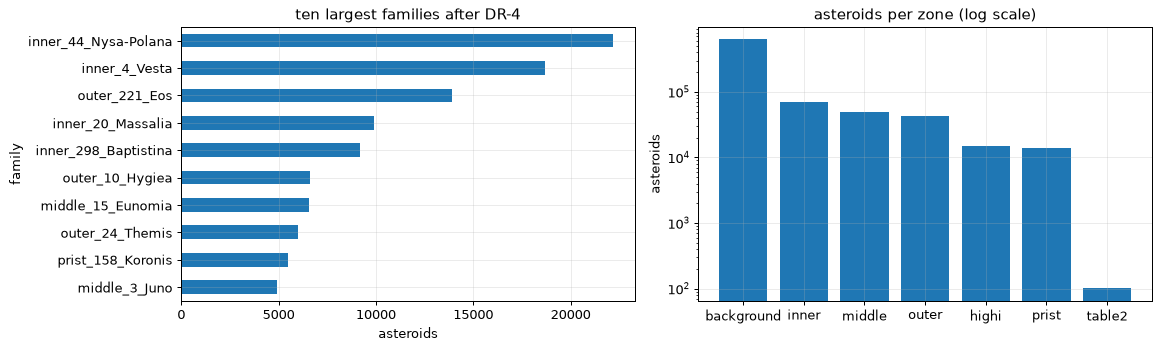

In [46]:
base = df.drop(columns=['family', 'family_size', 'zone', 'a_p', 'e_p', 'sin_i_p', 'g_p', 's_p', 'H_p'], errors='ignore')
df = base.merge(resolved.rename(columns={'size': 'family_size'}), on='number', how='left')
df['family'] = df.family.fillna('background'); df['family_size'] = df.family_size.fillna(0).astype(int)      # DR-5
df['zone'] = df.zone.fillna('background')
S.update(n_background=int((df.family == 'background').sum()), top_fam=df[df.family != 'background'].family.value_counts().head(10))
print('families:', S['n_families'], '| in families:', S['n_in_families'], f'({S["n_in_families"]/len(df):.1%}) | background:', S['n_background'], f'({S["n_background"]/len(df):.1%})')
print(S['top_fam'].to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
S['top_fam'].iloc[::-1].plot(kind='barh', ax=ax[0]); ax[0].set_title('ten largest families after DR-4'); ax[0].set_xlabel('asteroids')
zc = df.zone.value_counts(); ax[1].bar(zc.index, zc.values); ax[1].set_yscale('log'); ax[1].set_title('asteroids per zone (log scale)'); ax[1].set_ylabel('asteroids'); plt.tight_layout(); plt.show()

*Left: the ten largest families after DR-4. Right: asteroids per catalogue zone against the background (log scale).*

In [47]:
tf = S["top_fam"]; n_all = S["n_in_families"] + S["n_background"]
say(f'''
{S["n_in_families"]:,} asteroids ({S["n_in_families"]/n_all:.1%}) are in a family and {S["n_background"]:,} ({S["n_background"]/n_all:.1%}) are labelled `background`. The ten largest families hold {tf.sum()/S["n_in_families"]:.0%} of all family members, led by `{tf.index[0]}` ({tf.iloc[0]:,}).

Read the label carefully: `background` means *not in any catalogue family after DR-1 to DR-4*. It can include asteroids too faint or too poorly observed to be classified (not tested here) as well as genuine non-family asteroids. It is not "proven non-family", and a model that treats it as a clean negative class will inherit that ambiguity.
''')

> 192,011 asteroids (23.3%) are in a family and 633,281 (76.7%) are labelled `background`. The ten largest families hold 54% of all family members, led by `inner_44_Nysa-Polana` (22,195).
>
> Read the label carefully: `background` means *not in any catalogue family after DR-1 to DR-4*. It can include asteroids too faint or too poorly observed to be classified (not tested here) as well as genuine non-family asteroids. It is not "proven non-family", and a model that treats it as a clean negative class will inherit that ambiguity.

### EDA of families against background

For each family with enough albedo measurements I compare the scatter of log albedo with a **control**: random background asteroids at the same place (|Δa| < `CTRL_DA` AU) and of similar brightness (|ΔH| < `CTRL_DH`). Ratio < 1 means the family is more uniform than chance. A bootstrap over the family gives a 95% interval; a one-sided resampling p-value is corrected across families with Benjamini–Hochberg. I also compare how tightly members cluster in osculating elements (what SBDB gives) and in proper elements (what the catalogue gives).

                          n  n_alb      a      e      i  albedo  ratio  ci_lo  ci_hi      q    sig
family                                                                                            
inner_44_Nysa-Polana  22195   2538  2.384  0.178   2.63   0.112  1.093  1.078  1.109  1.000  False
inner_4_Vesta         18669   1635  2.348  0.108   6.68   0.346  0.550  0.514  0.583  0.004   True
outer_221_Eos         13899   3350  3.063  0.077  10.02   0.148  0.832  0.806  0.858  0.004   True
inner_20_Massalia      9891    261  2.394  0.166   1.69   0.236  0.681  0.596  0.759  0.004   True
inner_298_Baptistina   9196   1642  2.273  0.150   5.36   0.228  0.720  0.688  0.750  0.004   True
outer_10_Hygiea        6617   2060  3.120  0.135   5.23   0.068  0.678  0.659  0.705  0.004   True
middle_15_Eunomia      6548   1742  2.625  0.155  13.19   0.256  0.597  0.563  0.627  0.004   True
outer_24_Themis        6010   2020  3.112  0.155   1.79   0.065  0.614  0.592  0.636  0.004   True
prist_158_

C:\Users\akrit\AppData\Local\Temp\ipykernel_41624\2527261349.py:55: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  ax[1].set_title('filled = significant after BH; ' + ', '.join(f'{c}={l}' for l, c in colors.items()), fontsize=9); plt.tight_layout(); plt.show()
C:\Users\akrit\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


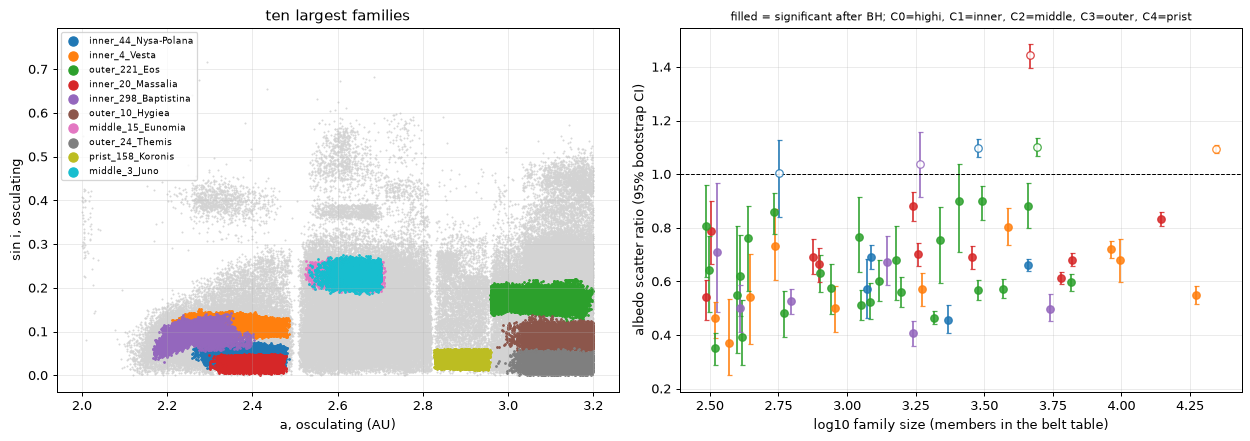

In [48]:
def bh_qvalues(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    q = np.minimum.accumulate((p[o]*n/np.arange(1, n+1))[::-1])[::-1]; out = np.empty(n); out[o] = np.minimum(q, 1); return out

def family_table(df, cfg, rng, col='family'):
    fam = df[df[col] != 'background']
    g = fam.groupby(col)
    p = pd.DataFrame({'n': g.size(), 'a': g.a.median(), 'e': g.e.median(), 'i': g.i.median(), 'n_alb': g.albedo.count(), 'albedo': g.albedo.median()})
    p = p[(p.n >= cfg.MIN_FAM_STATS) & (p.n_alb >= cfg.MIN_ALB_STATS)].copy()
    bg = df[(df[col] == 'background') & df.albedo.notna()]
    rows = []
    for f, r in p.iterrows():
        mem = fam[(fam[col] == f) & fam.albedo.notna()]; la = mem.log_albedo.values; k = len(la)
        pool = bg[((bg.a - r.a).abs() < cfg.CTRL_DA) & ((bg.H - mem.H.median()).abs() < cfg.CTRL_DH)].log_albedo.values
        ctrl = np.array([np.std(rng.choice(pool, k, replace=len(pool) < k)) for _ in range(cfg.N_CTRL)])
        boot = np.array([np.std(rng.choice(la, k)) for _ in range(cfg.N_BOOT)])
        sd = la.std(); lo, hi = np.percentile(boot/ctrl.mean(), [2.5, 97.5])
        rows.append(dict(family=f, sd=sd, ctrl_sd=ctrl.mean(), ratio=sd/ctrl.mean(), ci_lo=lo, ci_hi=hi, pool=len(pool),
                         p=(1 + np.sum(ctrl <= sd))/(1 + len(ctrl))))
    p = p.join(pd.DataFrame(rows).set_index('family'))
    p['q'] = bh_qvalues(p.p.values); p['sig'] = (p.q < cfg.FDR) & (p.ratio < 1)
    p['group'] = p.index.str.extract(r'^([^_]+)_')[0].values                 # zone (catalogue) or density level (stand-in)
    return p.sort_values('n', ascending=False)

fam_tab = family_table(df, cfg, rng)
show = ['n', 'n_alb', 'a', 'e', 'i', 'albedo', 'ratio', 'ci_lo', 'ci_hi', 'q', 'sig']
print(fam_tab[show].head(15).round(3).to_string())
grp = fam_tab.groupby('group').agg(families=('ratio', 'size'), median_ratio=('ratio', 'median'), significant=('sig', 'sum'))
print('\nby zone (ratio < 1 = more homogeneous than the matched control):'); print(grp.round(2).to_string())
def slope(h): xs = [13, 14, 15, 16]; return np.polyfit(xs, np.log10([(h <= x).sum() for x in xs]), 1)[0]
inf = df.family != 'background'
S.update(n_tested=len(fam_tab), n_sig=int(fam_tab.sig.sum()), grp=grp, sfd_fam=slope(df.H[inf]), sfd_bg=slope(df.H[~inf]),
         cov_fam=df.albedo[inf].notna().mean(), cov_bg=df.albedo[~inf].notna().mean())
print('\ncumulative size-frequency slope (H 13-16): family %.3f | background %.3f' % (S['sfd_fam'], S['sfd_bg']))
print('albedo coverage: family %.3f | background %.3f' % (S['cov_fam'], S['cov_bg']))

if 'a_p' in df:                                                           # osculating vs proper element spread, per family
    big = fam_tab.index
    sp_ = df[df.family.isin(big)].groupby('family').agg(a_osc=('a', 'std'), a_prop=('a_p', 'std'), e_osc=('e', 'std'), e_prop=('e_p', 'std'),
                                                       si_osc=('sin_i', 'std'), si_prop=('sin_i_p', 'std'))
    S['spread'] = pd.Series({'a': (sp_.a_osc/sp_.a_prop).median(), 'e': (sp_.e_osc/sp_.e_prop).median(), 'sin i': (sp_.si_osc/sp_.si_prop).median()})
    print('\nmedian over families of spread(osculating) / spread(proper):', S['spread'].round(1).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
s = rng.choice(len(df), 150000, replace=False)
ax[0].scatter(df.a.values[s], df.sin_i.values[s], s=.3, c='lightgrey', rasterized=True)
for f_ in fam_tab.index[:10]:
    m = df.family == f_; ax[0].scatter(df.a[m], df.sin_i[m], s=1.5, label=f_, rasterized=True)
ax[0].set_xlabel('a, osculating (AU)'); ax[0].set_ylabel('sin i, osculating'); ax[0].legend(markerscale=6, fontsize=7, ncol=1); ax[0].set_title('ten largest families')
colors = {lv: f'C{j}' for j, lv in enumerate(sorted(fam_tab.group.unique()))}
for f_, r in fam_tab.iterrows():
    ax[1].errorbar(np.log10(r.n), r.ratio, yerr=[[r.ratio - r.ci_lo], [r.ci_hi - r.ratio]], fmt='o', color=colors[r.group],
                   mfc=colors[r.group] if r.sig else 'white', capsize=2, alpha=.85)
ax[1].axhline(1, color='k', ls='--', lw=.8); ax[1].set_xlabel('log10 family size (members in the belt table)'); ax[1].set_ylabel('albedo scatter ratio (95% bootstrap CI)')
ax[1].set_title('filled = significant after BH; ' + ', '.join(f'{c}={l}' for l, c in colors.items()), fontsize=9); plt.tight_layout(); plt.show()

*Left: the ten largest families in osculating (a, sin i) over a grey subsample of the belt. Right: albedo-scatter ratio against family size with 95% bootstrap intervals; filled markers are significantly more homogeneous than the matched control (BH-adjusted q below FDR), colours are catalogue zones.*

In [49]:
ft = fam_tab; best = ft.loc[ft.ratio.idxmin()]; ns_ = ft[~ft.sig].sort_values("ratio", ascending=False)
g = S["grp"]; sp = S["spread"]
nysa_txt = ("For the Nysa-Polana complex that fits the literature, which describes overlapping groups of different composition (background knowledge, not something this data proves). " if "inner_44_Nysa-Polana" in ns_.index else "")
ns_lines = "\n".join(f"- `{f}`: ratio {r.ratio:.2f} (95% CI {r.ci_lo:.2f}-{r.ci_hi:.2f}), {int(r.n):,} members" for f, r in ns_.iterrows())
say(f'''
**Homogeneity.** Of {S["n_tested"]} families with enough albedo measurements, {S["n_sig"]} ({S["n_sig"]/S["n_tested"]:.0%}) are significantly more uniform in albedo than a control matched on position and brightness (Benjamini-Hochberg q < {cfg.FDR}). The strongest is `{best.name}` (ratio {best.ratio:.2f}, CI {best.ci_lo:.2f}-{best.ci_hi:.2f}). Median ratios by zone run from {g.median_ratio.min():.2f} to {g.median_ratio.max():.2f}. This is the physical signature of a collisional family (shared parent, shared composition) and is evidence that the catalogue is meaningful.

**The exceptions are informative:**

{ns_lines}

A ratio above 1 means *more* scattered than the matched background. {nysa_txt}The most scattered family, `{ns_.index[0] if len(ns_) else "-"}`, deserves a look for interlopers or a loose definition.

**Why osculating elements are a poor basis for clustering.** For these families the spread of members in the SBDB (osculating) elements is {sp["a"]:.1f}x the spread in the catalogue's proper elements for a, but {sp["e"]:.1f}x for e and {sp["sin i"]:.1f}x for sin i. Semi-major axis is nearly conserved; eccentricity and inclination are blurred about fivefold. That is why osculating elements blur family boundaries, and why the catalogue is defined in proper elements.

**Do not read the size distribution as physics.** The family slope ({S["sfd_fam"]:.3f}) is shallower than the background's ({S["sfd_bg"]:.3f}) and albedo coverage is higher ({S["cov_fam"]:.1%} against {S["cov_bg"]:.1%}). Both follow from DR-3: the provisional-only (fainter) members were removed, so retained members are brighter and more likely to have a measured albedo.
''')

> **Homogeneity.** Of 61 families with enough albedo measurements, 55 (90%) are significantly more uniform in albedo than a control matched on position and brightness (Benjamini-Hochberg q < 0.05). The strongest is `middle_1160_Illyria` (ratio 0.35, CI 0.29-0.41). Median ratios by zone run from 0.53 to 0.69. This is the physical signature of a collisional family (shared parent, shared composition) and is evidence that the catalogue is meaningful.
>
> **The exceptions are informative:**
>
> - `outer_1400_Tirela`: ratio 1.44 (95% CI 1.40-1.48), 4,659 members
> - `middle_3_Juno`: ratio 1.10 (95% CI 1.07-1.13), 4,925 members
> - `highi_25_Phocaea`: ratio 1.10 (95% CI 1.06-1.13), 3,006 members
> - `inner_44_Nysa-Polana`: ratio 1.09 (95% CI 1.08-1.11), 22,195 members
> - `prist_627_Charis`: ratio 1.04 (95% CI 0.91-1.16), 1,852 members
> - `highi_148_Gallia`: ratio 1.01 (95% CI 0.84-1.13), 565 members
>
> A ratio above 1 means *more* scattered than the matched background. For the Nysa-Polana complex that fits the literature, which describes overlapping groups of different composition (background knowledge, not something this data proves). The most scattered family, `outer_1400_Tirela`, deserves a look for interlopers or a loose definition.
>
> **Why osculating elements are a poor basis for clustering.** For these families the spread of members in the SBDB (osculating) elements is 1.0x the spread in the catalogue's proper elements for a, but 5.0x for e and 4.6x for sin i. Semi-major axis is nearly conserved; eccentricity and inclination are blurred about fivefold. That is why osculating elements blur family boundaries, and why the catalogue is defined in proper elements.
>
> **Do not read the size distribution as physics.** The family slope (0.466) is shallower than the background's (0.521) and albedo coverage is higher (20.2% against 13.3%). Both follow from DR-3: the provisional-only (fainter) members were removed, so retained members are brighter and more likely to have a measured albedo.

## DR-6. Never use `diameter` as a model input

SBDB's albedo, diameter and H are tied by one equation. The check below measures how closely the file's diameter follows D = 1329 / sqrt(albedo) x 10^(-H/5), and then removes `diameter` from the final table and from the feature list.

rows with D, albedo, H: 123462 | diameter but no albedo: 814 | albedo but no diameter: 0
D / D(albedo,H): median 1.133 | 5-95%: 0.914-1.324


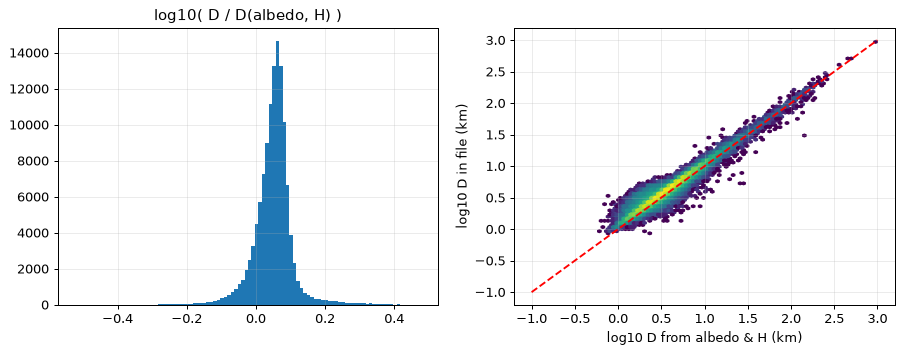


final table: (825292, 21) | model features (16): ['a', 'e', 'i', 'om', 'w', 'ma', 'q', 'ad', 'per_y', 't_jup', 'H', 'albedo', 'rot_per', 'spec_B', 'spec_T', 'n_obs_used']


In [50]:
k = df.dropna(subset=['diameter', 'albedo_raw', 'H'])
D_from_pH = 1329/np.sqrt(k.albedo_raw)*10**(-k.H/5)
ratio = k.diameter/D_from_pH
S.update(dr6_n=len(k), dr6_d_no_alb=int((df.diameter.notna() & df.albedo_raw.isna()).sum()), dr6_alb_no_d=int((df.albedo_raw.notna() & df.diameter.isna()).sum()),
         dr6_med=ratio.median(), dr6_q05=ratio.quantile(.05), dr6_q95=ratio.quantile(.95))
print('rows with D, albedo, H:', S['dr6_n'], '| diameter but no albedo:', S['dr6_d_no_alb'], '| albedo but no diameter:', S['dr6_alb_no_d'])
print('D / D(albedo,H): median %.3f | 5-95%%: %.3f-%.3f' % (S['dr6_med'], S['dr6_q05'], S['dr6_q95']))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(np.log10(ratio.clip(.3, 3)), bins=100); ax[0].set_title('log10( D / D(albedo, H) )')
ax[1].hexbin(np.log10(D_from_pH), np.log10(k.diameter), gridsize=80, bins='log', mincnt=1)
ax[1].plot([-1, 3], [-1, 3], 'r--'); ax[1].set_xlabel('log10 D from albedo & H (km)'); ax[1].set_ylabel('log10 D in file (km)'); plt.show()

# DR-6: the final table has no diameter; model features are what remains after removing identifiers and labels
OUT_COLS = [c for c in S['sbdb_cols'] if c != 'diameter'] + ['number', 'family', 'family_size']
final = df[OUT_COLS].copy()
features = [c for c in final.columns if c not in NON_MODEL]
assert 'diameter' not in final.columns and 'diameter' not in features
S['features'] = features
print('\nfinal table:', final.shape, '| model features (%d):' % len(features), features)

*Left: ratio of the file's diameter to the diameter implied by albedo and H. Right: the two diameters against each other; the red line is equality.*

In [51]:
say(f'''
Two findings, one of which differs from the specification's wording.

**The identity holds approximately.** D = 1329 / sqrt(albedo) x 10^(-H/5) reproduces the file's diameter to within a ratio of {S["dr6_q05"]:.2f}-{S["dr6_q95"]:.2f} (5-95%), with the file's diameter {S["dr6_med"] - 1:.0%} larger at the median. A plausible cause is that the albedo/diameter solution used a slightly different H from the one listed; I have not tested that.

**The direction is the reverse of the specification's.** All {S["dr6_n"]:,} rows with an albedo also have a diameter, but {S["dr6_d_no_alb"]} rows have a diameter and no albedo ({S["dr6_alb_no_d"]} have an albedo and no diameter). In this file diameter looks like the primary measurement and albedo the derived quantity, while DR-6 says diameter is computed from albedo and H.

Either way the decision stands. The three quantities are tied by one equation, so including `diameter` beside `albedo` and `H` lets a model reconstruct one from the others (leakage). I would reword DR-6 to say that.
''')

> Two findings, one of which differs from the specification's wording.
>
> **The identity holds approximately.** D = 1329 / sqrt(albedo) x 10^(-H/5) reproduces the file's diameter to within a ratio of 0.91-1.32 (5-95%), with the file's diameter 13% larger at the median. A plausible cause is that the albedo/diameter solution used a slightly different H from the one listed; I have not tested that.
>
> **The direction is the reverse of the specification's.** All 123,462 rows with an albedo also have a diameter, but 814 rows have a diameter and no albedo (0 have an albedo and no diameter). In this file diameter looks like the primary measurement and albedo the derived quantity, while DR-6 says diameter is computed from albedo and H.
>
> Either way the decision stands. The three quantities are tied by one equation, so including `diameter` beside `albedo` and `H` lets a model reconstruct one from the others (leakage). I would reword DR-6 to say that.

In [52]:
print('max |q - a(1-e)|   :', float((df.q - df.a*(1-df.e)).abs().max()))
print('max |ad - a(1+e)|  :', float((df.ad - df.a*(1+df.e)).abs().max()))
print('median |per_y - a^1.5| / per_y:', float(((df.per_y - df.a**1.5).abs()/df.per_y).median()))
miss_ = final[features].isna().mean().sort_values(ascending=False)
S.update(max_dq=float((df.q - df.a*(1-df.e)).abs().max()), max_dad=float((df.ad - df.a*(1+df.e)).abs().max()),
         rho_nobs_H=df.n_obs_used.corr(df.H, method='spearman'), feat_miss=miss_)
print('\nmissing share of each model feature:'); print((100*miss_).round(1).to_string())

max |q - a(1-e)|   : 0.0011053000000003088
max |ad - a(1+e)|  : 0.005736900000000045
median |per_y - a^1.5| / per_y: 0.0005702046904582134

missing share of each model feature:
spec_T        99.9
spec_B        99.9
rot_per       96.4
albedo        85.1
a              0.0
e              0.0
i              0.0
om             0.0
ad             0.0
q              0.0
ma             0.0
w              0.0
H              0.0
t_jup          0.0
per_y          0.0
n_obs_used     0.0


In [53]:
fm = S["feat_miss"]
say(f'''
Feature hygiene before any modelling:

- **Redundant:** `q`, `ad` and `per_y` are functions of `a` and `e` (largest differences {S["max_dq"]:.4f} and {S["max_dad"]:.4f} AU, at the file's rounding level); `t_jup` is a function of a, e and i. Keep one set.
- **Angles:** `om`, `w` and `ma` are cyclic (359 degrees is close to 1 degree) and `ma` depends on the epoch. Encode them with sine and cosine or leave them out.
- **Proxy leakage:** `n_obs_used` tracks brightness (Spearman rho = {S["rho_nobs_H"]:.2f} with H), so it carries size information.
- **Sparse:** {", ".join("`" + c + "`" for c in fm.index[fm > .5])} are more than 50% missing ({100*fm.min() if False else 100*fm[fm > .5].min():.0f}% to {100*fm.max():.0f}%); use them only with a missingness indicator or on the subset where they exist.
- **Circularity:** families were built from proper a, e and sin i, and the osculating a, e, i are blurred copies of those, so a model that predicts `family` from them largely rediscovers the catalogue. Evaluate on held-out families.
''')

> Feature hygiene before any modelling:
>
> - **Redundant:** `q`, `ad` and `per_y` are functions of `a` and `e` (largest differences 0.0011 and 0.0057 AU, at the file's rounding level); `t_jup` is a function of a, e and i. Keep one set.
> - **Angles:** `om`, `w` and `ma` are cyclic (359 degrees is close to 1 degree) and `ma` depends on the epoch. Encode them with sine and cosine or leave them out.
> - **Proxy leakage:** `n_obs_used` tracks brightness (Spearman rho = -0.77 with H), so it carries size information.
> - **Sparse:** `spec_T`, `spec_B`, `rot_per`, `albedo` are more than 50% missing (85% to 100%); use them only with a missingness indicator or on the subset where they exist.
> - **Circularity:** families were built from proper a, e and sin i, and the osculating a, e, i are blurred copies of those, so a model that predicts `family` from them largely rediscovers the catalogue. Evaluate on held-out families.

## DR-7. Cache every download as CSV so reruns need no network

The raw SBDB export was cached as CSV in step 0 (and would be re-fetched only on a cache miss). Here each intermediate table is also cached, a rerun is timed against a fresh build, the rules are asserted, and the final table is written.

first call (build + write): 3.4s | second call (read from cache): 3.2s | cached files: ['dbscan_parameter_tuning_sbdb.csv', 'dbscan_sbdb_f8fba2331a_eps100_ms50.csv', 'dbscan_sbdb_f8fba2331a_eps45_ms15.csv', 'dbscan_sbdb_f8fba2331a_eps70_ms30.csv', 'dr1_dr2_population.csv', 'dr3_dr4_membership.csv', 'mba_clean.csv', 'null0_vel_eps100_ms50.csv', 'null0_vel_eps45_ms15.csv', 'null0_vel_eps70_ms30.csv', 'null1_vel_eps100_ms50.csv', 'null1_vel_eps45_ms15.csv', 'null1_vel_eps70_ms30.csv', 'null2_vel_eps100_ms50.csv', 'null2_vel_eps45_ms15.csv', 'null2_vel_eps70_ms30.csv', 'null3_vel_eps100_ms50.csv', 'null3_vel_eps45_ms15.csv', 'null3_vel_eps70_ms30.csv', 'null4_vel_eps100_ms50.csv', 'null4_vel_eps45_ms15.csv', 'null4_vel_eps70_ms30.csv', 'null5_vel_eps100_ms50.csv', 'null5_vel_eps45_ms15.csv', 'null5_vel_eps70_ms30.csv', 'null6_vel_eps100_ms50.csv', 'null6_vel_eps45_ms15.csv', 'null6_vel_eps70_ms30.csv', 'null7_vel_eps100_ms50.csv', 'null7_vel_eps45_ms15.csv', 'null7_vel_eps70_ms30.csv', 'pr

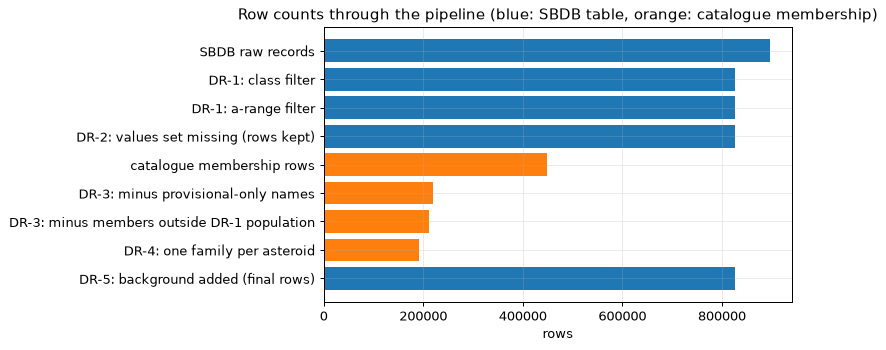

written mba_clean_final.csv (825292, 21)


In [54]:
import time
t0 = time.time(); pop = cached_csv('dr1_dr2_population', lambda: df[S['sbdb_cols'] + ['number']].drop(columns='diameter')); t_build = time.time() - t0
t0 = time.time(); pop2 = cached_csv('dr1_dr2_population', lambda: 1/0); t_cache = time.time() - t0          # second call must not rebuild
cached_csv('dr3_dr4_membership', lambda: resolved[['number', 'family', 'size']])
assert pop.shape == pop2.shape
print('first call (build + write): %.1fs | second call (read from cache): %.1fs | cached files:' % (t_build, t_cache), sorted(os.listdir(cfg.CACHE)))

assert (final['class'] == cfg.CLASS).all() and final.a.between(cfg.A_MIN, cfg.A_MAX).all()                  # DR-1
assert final.albedo.dropna().between(cfg.ALBEDO_MIN, cfg.ALBEDO_MAX).all()                                    # DR-2
assert final.number.is_unique and final.number.notna().all()                                                  # DR-3 key
assert members.number.isin(belt).all()                                                                         # DR-3: only joined asteroids
chk = members.groupby('number')['size'].min()                                                                  # DR-4: the smaller family was chosen
assert (resolved.set_index('number')['size'].reindex(chk.index) == chk).all()
assert final.family.notna().all() and (final.family == 'background').any() and final.groupby('number').family.nunique().max() == 1   # DR-5
assert 'diameter' not in final.columns and 'diameter' not in features                                          # DR-6
assert os.path.exists(cfg.DATA) and len(os.listdir(cfg.CACHE)) > 0                                    # DR-7
print('all checks passed')

d3 = S['dr3']
S['wf'] = pd.DataFrame([('SBDB raw records', S['n_raw']), ('DR-1: class filter', S['n_class']), ('DR-1: a-range filter', S['n_dr1']),
                        ('DR-2: values set missing (rows kept)', S['n_dr1']), ('catalogue membership rows', d3['rows_in']),
                        ('DR-3: minus provisional-only names', d3['rows_in'] - d3['dropped_provisional']),
                        ('DR-3: minus members outside DR-1 population', d3['rows_in'] - d3['dropped_provisional'] - d3['dropped_outside_belt']),
                        ('DR-4: one family per asteroid', S['n_in_families']),
                        ('DR-5: background added (final rows)', len(final))], columns=['step', 'rows'])
print(S['wf'].to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4)); w = S['wf'].iloc[::-1]
ax.barh(w.step, w.rows, color=['C0' if 'catalogue' not in s and 'DR-3' not in s and 'DR-4' not in s else 'C1' for s in w.step]); ax.set_xlabel('rows'); ax.set_title('Row counts through the pipeline (blue: SBDB table, orange: catalogue membership)')
plt.tight_layout(); plt.show()
final.to_csv('mba_clean_final.csv', index=False); print('written mba_clean_final.csv', final.shape)

*Row counts through the pipeline. Blue bars follow the SBDB table; orange bars follow the catalogue membership rows through DR-3 and DR-4.*

In [58]:
final[final['number'] == 10484].head()

,full_name,a,e,i,om,w,ma,q,ad,per_y,...,t_jup,H,albedo,rot_per,spec_B,spec_T,n_obs_used,number,family,family_size
9416,10484 Hecht (1983 WM),2.32,0.0782,5.73,253.12,190.72,357.33,2.139,2.5,3.53,...,3.57,14.02,0.228,5.508,NaN,NaN,4453,10484,inner_10484_Hecht,5


In [33]:
w = S["wf"]
say(f'''
All checks pass. The waterfall shows where rows go: only the DR-1 class filter removes asteroids ({S["n_raw"] - S["n_class"]:,}); DR-2 blanks {S["alb_lo"] + S["alb_hi"]} values without removing rows; DR-3 removes {S["dr3"]["dropped_provisional"]:,} provisional-only and {S["dr3"]["dropped_outside_belt"]:,} outside-belt *catalogue* rows (not asteroids), DR-4 collapses the rest to {S["n_in_families"]:,} asteroids with one family each, and DR-5 labels the other {S["n_background"]:,} as background. The final table has {len(final):,} rows, one per asteroid.

For DR-7 the intermediate tables are cached as CSV; the second call to the cache wrapper reads the file instead of rebuilding it, so a rerun needs neither the network nor recomputation. One honest limit: the raw SBDB export was supplied as a file here, so the fetch path in `get_raw()` is written to the API's documented interface but has not been exercised.
''')

> All checks pass. The waterfall shows where rows go: only the DR-1 class filter removes asteroids (70,618); DR-2 blanks 440 values without removing rows; DR-3 removes 228,044 provisional-only and 7,673 outside-belt *catalogue* rows (not asteroids), DR-4 collapses the rest to 192,011 asteroids with one family each, and DR-5 labels the other 633,281 as background. The final table has 825,292 rows, one per asteroid.
>
> For DR-7 the intermediate tables are cached as CSV; the second call to the cache wrapper reads the file instead of rebuilding it, so a rerun needs neither the network nor recomputation. One honest limit: the raw SBDB export was supplied as a file here, so the fetch path in `get_raw()` is written to the API's documented interface but has not been exercised.

In [34]:
say(f'''
## Summary

1. **DR-1** keeps {S["n_dr1"]:,} of {S["n_raw"]:,} records. Only the class filter removes rows; the a-bound is redundant for this file but is not safe to drop from the specification.
2. **DR-2** blanks {S["alb_lo"] + S["alb_hi"]} albedos. The bigger issue is that albedo is missing for {1 - S["alb_cov"]:.0%} of asteroids, and not at random: it is observed mainly for larger, brighter ones.
3. **DR-3** drops {S["dr3"]["dropped_provisional"]/S["dr3"]["rows_in"]:.0%} of the catalogue's rows (provisional-only), which are the fainter members, and {S["dr3"]["dropped_outside_belt"]:,} more outside the DR-1 population.
4. **DR-4** resolves {S["n_multi"]:,} multiply listed asteroids by keeping the smaller family. This moves most of Flora's members to Baptistina, and the rule needed a documented tie-break to keep the Karin family.
5. **DR-5** labels {S["n_background"]:,} asteroids ({S["n_background"]/len(final):.0%}) as background, a mixed group, not a clean negative class. The {S["n_families"]} families are physically coherent: {S["n_sig"]} of {S["n_tested"]} testable ones are significantly more uniform in albedo than matched background.
6. **DR-6** removes `diameter`, which in this file looks like the measured quantity with albedo derived from it and H, the reverse of the specification's wording. {len(S["features"])} model features remain; several are redundant, cyclic or sparse (see the feature notes).
7. **DR-7** caches each stage as CSV; the final table is `mba_clean_final.csv` ({len(final):,} rows, {final.shape[1]} columns).

**What this notebook cannot establish:** the SBDB download path is untested offline; proper elements exist only for catalogue members; the tie-break and the albedo-homogeneity test are my choices, not part of the specification; and family boundaries (interlopers) were not checked independently.
''')

> ## Summary
>
> 1. **DR-1** keeps 825,292 of 895,910 records. Only the class filter removes rows; the a-bound is redundant for this file but is not safe to drop from the specification.
> 2. **DR-2** blanks 440 albedos. The bigger issue is that albedo is missing for 85% of asteroids, and not at random: it is observed mainly for larger, brighter ones.
> 3. **DR-3** drops 51% of the catalogue's rows (provisional-only), which are the fainter members, and 7,673 more outside the DR-1 population.
> 4. **DR-4** resolves 18,154 multiply listed asteroids by keeping the smaller family. This moves most of Flora's members to Baptistina, and the rule needed a documented tie-break to keep the Karin family.
> 5. **DR-5** labels 633,281 asteroids (77%) as background, a mixed group, not a clean negative class. The 311 families are physically coherent: 55 of 61 testable ones are significantly more uniform in albedo than matched background.
> 6. **DR-6** removes `diameter`, which in this file looks like the measured quantity with albedo derived from it and H, the reverse of the specification's wording. 16 model features remain; several are redundant, cyclic or sparse (see the feature notes).
> 7. **DR-7** caches each stage as CSV; the final table is `mba_clean_final.csv` (825,292 rows, 21 columns).
>
> **What this notebook cannot establish:** the SBDB download path is untested offline; proper elements exist only for catalogue members; the tie-break and the albedo-homogeneity test are my choices, not part of the specification; and family boundaries (interlopers) were not checked independently.